# Paper comparison: IP attribution and corrected-label audit for the eight models

Run top to bottom in Google Colab. This notebook answers three questions about the completed eight-model comparison:

1. **Who produces the attack-labeled flows?** Every graph edge is joined to its raw NF-v3 row, so IPs come directly from the raw CSV. No saved `ip_map` is needed to decode them.
2. **What does each model actually alert on?** Alerts are decomposed by traffic group, documented campaign stage, destination host, and source IP.
3. **Do the conclusions survive the corrected labels?** The frozen rules in `nfv3_relabel.py` are applied to the same rows, and the cached scores of the eight models are evaluated against both label sets.

**This notebook does not train, run inference, or read graph tensors.** It requires the raw CSVs, the saved alignment indices, manifests, records, checkpoints, and validation/Test 1/Test 2 score caches. If a required cache is missing, rerun its original evaluation section.

**Interpretation boundaries.** The models were trained and thresholded on the original labels. Evaluating them on corrected labels measures how well their existing scores rank documented attack activity; it is not what those models would achieve if trained on corrected labels. That experiment needs the corrected graphs on `feat/fair-retrain-clean`. Test 2 has one validation-selected champion per model and was explored previously, so its comparisons are descriptive. Seed SD measures training variability on fixed captures, not uncertainty across campaigns. Group names describe endpoints and ports; they are not evidence of attacker intent. Results from the historical February ST-GNN checkpoint and from notebooks that decode IPs with the old `ip_map` files are not used.

## 1. Setup

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if importlib.util.find_spec('pyarrow') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'], check=True)
from google.colab import drive
drive.mount('/content/drive')

import gc
import hashlib
import ipaddress
import json
import pickle
import platform
import re
import urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

ROOT = Path('/content/drive/MyDrive/nids-mitre')
FACTORIAL_ROOT = ROOT / 'results_stgnn_memory_message_factorial_v1'
BASELINE_ROOT = ROOT / 'results_baseline_retraining_factorial_protocol_v1'
TEMPORAL_ROOT = ROOT / 'results_temporal_mlp_global_host_factorial_protocol_v1'
RAW_CSV = {'wed': ROOT / 'data/cicids2018-v3/cicids2018v3_wed2802.csv',
           'thu': ROOT / 'data/cicids2018-v3/cicids2018v3_thu0103.csv'}
RECOVERED_MAPS = {'wed': ROOT / 'dataset_processed/ip_map_day1_recovered.pkl',
                  'thu': ROOT / 'dataset_processed_thu0103/ip_map_day2_recovered.pkl'}
PAPER_MODELS = ['MLP', 'Global traffic MLP-GRU', 'Host history MLP-GRU', 'E-GraphSAGE', 'M0_P0', 'M0_P1', 'M1_P0', 'M1_P1']
MEMORY_MODELS = {'Host history MLP-GRU', 'M1_P0', 'M1_P1'}
VERIFY_CHECKPOINT_HASHES = True
BUDGET_FRACTIONS = [0.0001, 0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.10]
WINDOW_SECONDS = 30
TOP_SOURCES_TO_INSPECT = 10
MIN_GROUP_POSITIVES = 50
PR_GRID_POINTS = 5000

# The relabelling rules are pinned by commit and content hash.
RELABEL_COMMIT = 'aab4646bfd3480fee54b464802ee97477e3c027f'
RELABEL_SHA256 = '20a394ffa5017cbfcc13aa0b4c2b1d0cfc32554e44d0c82e4f2dfb5458a33b83'
RELABEL_URL = f'https://raw.githubusercontent.com/tatipar/temporalgnn-nids/{RELABEL_COMMIT}/code/python/utils/nfv3_relabel.py'
# Frozen outcome recorded in docs/nfv3-label-correction-v1.md on feat/fair-retrain-clean.
RAW_SHA256 = {'wed': 'bebab480e2578b31fa307efdc0dbee1ecc6f9d85406d582a1eaf8242703aba55', 'thu': '1d5847a0af491ca52aaf4bb665cbd75353b250687e035644fbe05c6afad6de60'}
EXPECTED_RULE_COUNTS = {'attempted_category_4_to_benign': 18, 'confirmed_dropbox_download': 48, 'confirmed_nmap_portscan': 111992, 'confirmed_victim_attacker_communication': 12, 'old_infilteration_to_benign': 136754, 'unchanged': 3931436}
EXPECTED_TRANSITIONS = {'0->0': 3931453, '0->1': 60655, '1->0': 136755, '1->1': 51397}

OUTPUT_ROOT = ROOT / 'results_comparison/paper_eight_models_ip_label_audit_v1'
ANALYSIS_RUN = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('run_%Y%m%dT%H%M%SZ')
ANALYSIS_RUN.mkdir(parents=True, exist_ok=False)

# Fixed colors: a model or traffic group keeps its hue in every figure.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MODEL_COLORS = dict(zip(PAPER_MODELS, SERIES))
INK, MUTED, RULE, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': RULE, 'axes.labelcolor': MUTED, 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': RULE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'legend.frameon': False, 'font.size': 10, 'axes.titlesize': 11, 'lines.linewidth': 2,
})

def slug(value):
    return re.sub(r'[^a-z0-9]+', '_', str(value).lower()).strip('_')

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(', ', ': ')).encode()).hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False))

def read_csv(path):
    return pd.read_csv(path, float_precision='round_trip')

def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(ANALYSIS_RUN / f'{name}.{extension}', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

input_inventory = []

def track(path, role):
    path = Path(path)
    input_inventory.append(dict(path=str(path), role=role, sha256=sha256_file(path)))

for path in (FACTORIAL_ROOT / 'manifest.json', BASELINE_ROOT / 'manifest.json', TEMPORAL_ROOT / 'manifest.json'):
    assert path.is_file(), f'Missing completed-run manifest: {path}'
factorial_manifest = json.loads((FACTORIAL_ROOT / 'manifest.json').read_text())
baseline_manifest = json.loads((BASELINE_ROOT / 'manifest.json').read_text())
temporal_manifest = json.loads((TEMPORAL_ROOT / 'manifest.json').read_text())
assert baseline_manifest['reference_manifest_file_sha256'] == sha256_file(FACTORIAL_ROOT / 'manifest.json')
assert temporal_manifest['reference_manifest_file_sha256'] == sha256_file(FACTORIAL_ROOT / 'manifest.json')
for manifest in (baseline_manifest, temporal_manifest):
    assert manifest['seeds'] == factorial_manifest['seeds']
    assert manifest['threshold_rule'] == factorial_manifest['threshold_rule']
    for tag in ('train', 'val', 'test1', 'test2'):
        for key in ('dataset_sha256', 'alignment_sha256'):
            assert manifest['splits'][tag][key] == factorial_manifest['splits'][tag][key], (tag, key)
SEEDS = list(factorial_manifest['seeds'])
assert SEEDS == [42, 123, 777, 2024, 99]
track(FACTORIAL_ROOT / 'manifest.json', 'factorial_manifest')
track(BASELINE_ROOT / 'manifest.json', 'baseline_manifest')
track(TEMPORAL_ROOT / 'manifest.json', 'temporal_manifest')
print('Output:', ANALYSIS_RUN)
print('No fitting, inference, or graph-file reads are performed.')

Mounted at /content/drive
Output: /content/drive/MyDrive/nids-mitre/results_comparison/paper_eight_models_ip_label_audit_v1/run_20261030T180304Z
No fitting, inference, or graph-file reads are performed.


## 2. Apply the frozen relabelling rules to the raw rows

`relabel_chunk` clears every old `Infilteration` label and then rebuilds positives from documented rules: the victim's Dropbox download, its communication with the attacker, and its Nmap scan, each restricted by IP and time. Attempted flows become benign. The rules need only raw columns, which is why they cannot be applied to graph tensors directly.

The raw CSV hashes and the rule and transition counts must reproduce the frozen correction record before anything else runs. Those counts cover all raw rows, including the rows with `0.0.0.0` endpoints that the graph builder removed.

Each flow is also placed in one mutually exclusive traffic group. Groups are evaluated in the order listed in `FLOW_GROUPS`.

In [2]:
module_path = ANALYSIS_RUN / 'nfv3_relabel.py'
urllib.request.urlretrieve(RELABEL_URL, module_path)
assert sha256_file(module_path) == RELABEL_SHA256, 'Relabelling rules changed'
relabel_spec = importlib.util.spec_from_file_location('nfv3_relabel', module_path)
relabel = importlib.util.module_from_spec(relabel_spec)
sys.modules['nfv3_relabel'] = relabel
relabel_spec.loader.exec_module(relabel)
print('Rule version:', relabel.RULE_VERSION)

RAW_COLUMNS = ['FLOW_START_TIME', 'FLOW_START_MILLISECONDS', 'IPV4_SRC_ADDR', 'L4_SRC_PORT',
               'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'IN_BYTES', 'Attack']
DAY_OF_TAG = {'train': 'wed', 'val': 'wed', 'test1': 'wed', 'test2': 'thu'}
INFECTED_HOST = {'wed': '172.31.69.24', 'thu': '172.31.69.13'}
ATTACKER = '13.58.225.34'
RESOLVER = '172.31.0.2'
SCAN_TARGETS = {'wed': relabel.NMAP_DESTINATIONS_2802, 'thu': relabel.NMAP_DESTINATIONS_0103}
DROPBOX_ENDPOINTS = relabel.DROPBOX_2802 | relabel.DROPBOX_0103
INTERNAL_NETWORK = ipaddress.ip_network('172.31.0.0/16')
FLOW_GROUPS = ['documented_nmap', 'documented_dropbox', 'documented_victim_attacker', 'attempted_artifact',
               'attacker_to_infected_host', 'infected_host_other', 'scan_target_to_resolver_dns',
               'other_to_resolver_dns', 'to_scan_target', 'from_scan_target', 'other_traffic']

def flow_groups(frame, day):
    infected = INFECTED_HOST[day]
    src_infected = frame.src_ip.eq(infected)
    src_target = frame.src_ip.isin(SCAN_TARGETS[day])
    dst_target = frame.dst_ip.isin(SCAN_TARGETS[day])
    to_resolver_dns = frame.dst_ip.eq(RESOLVER) & frame.dst_port.eq(53)
    conditions = [
        frame.correction_rule.eq('confirmed_nmap_portscan'),
        frame.correction_rule.eq('confirmed_dropbox_download'),
        frame.correction_rule.eq('confirmed_victim_attacker_communication'),
        frame.correction_rule.isin(['attempted_category_4_to_benign', 'attempted_category_0_to_benign']),
        frame.src_ip.eq(ATTACKER) & frame.dst_ip.eq(infected),
        src_infected, src_target & to_resolver_dns, to_resolver_dns, dst_target, src_target,
    ]
    return pd.Categorical(np.select(conditions, FLOW_GROUPS[:-1], default=FLOW_GROUPS[-1]),
                          categories=FLOW_GROUPS)

def ip_role(ip, day):
    if ip == INFECTED_HOST[day]:
        return 'infected host'
    if ip == ATTACKER:
        return 'documented attacker'
    if ip == RESOLVER:
        return 'internal resolver'
    if ip in SCAN_TARGETS[day]:
        return 'scan target'
    if ip in DROPBOX_ENDPOINTS:
        return 'Dropbox endpoint'
    return 'other internal' if ipaddress.ip_address(ip) in INTERNAL_NETWORK else 'external'

def integer_column(values, dtype):
    # Rows removed by the graph builder may have empty ports.
    return pd.to_numeric(values, errors='coerce').fillna(-1).to_numpy(dtype=dtype)

def load_raw_day(day):
    assert RAW_CSV[day].is_file(), f'Missing raw CSV: {RAW_CSV[day]}'
    assert sha256_file(RAW_CSV[day]) == RAW_SHA256[day], f'Raw CSV changed: {day}'
    track(RAW_CSV[day], f'{day}_raw_csv')
    parts, offset = [], 0
    for chunk in pd.read_csv(RAW_CSV[day], usecols=RAW_COLUMNS, chunksize=500_000, low_memory=False):
        corrected = relabel.relabel_chunk(chunk, forward_bytes_column='IN_BYTES')
        parts.append(pd.DataFrame(dict(
            raw_csv_row=np.arange(offset, offset + len(chunk), dtype=np.int64),
            flow_start=pd.to_datetime(corrected.FLOW_START_TIME, errors='coerce'),
            src_ip=corrected.IPV4_SRC_ADDR.astype(str).to_numpy(),
            dst_ip=corrected.IPV4_DST_ADDR.astype(str).to_numpy(),
            src_port=integer_column(corrected.L4_SRC_PORT, np.int32),
            dst_port=integer_column(corrected.L4_DST_PORT, np.int32),
            protocol=integer_column(corrected.PROTOCOL, np.int16),
            native_label=corrected.Attack.eq('Infilteration').to_numpy(dtype=np.int8),
            corrected_label=corrected.binary_target.to_numpy(dtype=np.int8),
            correction_rule=corrected.correction_rule.to_numpy(),
        )))
        offset += len(chunk)
    frame = pd.concat(parts, ignore_index=True)
    rule_counts = frame.correction_rule.value_counts().to_dict()
    transitions = (frame.native_label.astype(str) + '->' + frame.corrected_label.astype(str)).value_counts().to_dict()
    frame = frame.loc[frame.src_ip.ne('0.0.0.0') & frame.dst_ip.ne('0.0.0.0')].reset_index(drop=True)
    assert frame.flow_start.notna().all(), 'Invalid raw start timestamp'
    return frame, rule_counts, transitions

raw_days, all_rules, all_transitions = {}, {}, {}
for day in ('wed', 'thu'):
    raw_days[day], rule_counts, transitions = load_raw_day(day)
    for key, value in rule_counts.items():
        all_rules[key] = all_rules.get(key, 0) + value
    for key, value in transitions.items():
        all_transitions[key] = all_transitions.get(key, 0) + value
    print(day, 'rows kept for graphs:', len(raw_days[day]))
assert all_rules == EXPECTED_RULE_COUNTS, all_rules
assert all_transitions == EXPECTED_TRANSITIONS, all_transitions
print('Frozen relabelling counts reproduced exactly.')

for day, frame in raw_days.items():
    frame['flow_group'] = flow_groups(frame, day)
    frame['correction_rule'] = frame.correction_rule.astype('category')
    for column in ('src_ip', 'dst_ip'):
        frame[column] = frame[column].astype('category')

Rule version: cse-cic-ids2018-infiltration-v1
wed rows kept for graphs: 2022007
thu rows kept for graphs: 2135957
Frozen relabelling counts reproduced exactly.


## 3. Join every graph edge to its raw row

The graph builder grouped rows by flow-start window and kept CSV order inside each window, so `(window_id, edge_index_in_graph)` identifies a raw row. The neighborhood audit verified that reconstruction against every edge attribute. Here the join is checked again from independent evidence: every edge must find one row, labels must match, and each `source_gid` or `destination_gid` must map to exactly one IP. A misaligned join cannot satisfy the last check.

In [3]:
contexts = {}
first_window = {'wed': pd.Timestamp(factorial_manifest['splits']['train']['first_window']),
                'thu': pd.Timestamp(factorial_manifest['splits']['test2']['first_window'])}
for day, frame in raw_days.items():
    offset = frame.flow_start - first_window[day]
    frame['window_id'] = (offset // pd.Timedelta(seconds=WINDOW_SECONDS)).astype(np.int32)
    assert frame.window_id.ge(0).all(), day
    frame['edge_index_in_graph'] = frame.groupby('window_id', sort=False).cumcount().astype(np.int32)

day_edges = {'wed': 0, 'thu': 0}
for tag in ('train', 'val', 'test1', 'test2'):
    day = DAY_OF_TAG[tag]
    spec = factorial_manifest['splits'][tag]
    path = FACTORIAL_ROOT / 'alignment' / f'{tag}_flows.parquet'
    graph_path = FACTORIAL_ROOT / 'alignment' / f'{tag}_graphs.csv'
    assert sha256_file(path) == spec['alignment_sha256']
    assert sha256_file(graph_path) == spec['inventory_sha256']
    track(path, f'{tag}_flow_alignment')
    track(graph_path, f'{tag}_graph_inventory')
    index = pd.read_parquet(path).sort_values('flow_index').reset_index(drop=True)
    assert np.array_equal(index.flow_index.to_numpy(), np.arange(len(index)))
    assert not index.duplicated(['window_id', 'edge_index_in_graph']).any()
    assert len(index) == spec['flows'] and int(index.label.sum()) == spec['attacks']
    expected_start = first_window[day].value + index.window_id.to_numpy(np.int64) * WINDOW_SECONDS * 1_000_000_000
    assert np.array_equal(index.window_start_ns.to_numpy(), expected_start), f'{tag}: window clock mismatch'
    table = index.merge(raw_days[day], on=['window_id', 'edge_index_in_graph'], how='left', validate='one_to_one')
    assert table.raw_csv_row.notna().all(), f'{tag}: edge without raw row'
    assert table.label.eq(table.native_label).all(), f'{tag}: label mismatch after join'
    assert np.array_equal(table.flow_index.to_numpy(), np.arange(len(table))), f'{tag}: join changed flow order'
    table['raw_csv_row'] = table.raw_csv_row.astype(np.int64)
    day_edges[day] += len(table)
    contexts[tag] = dict(
        table=table, y_native=table.native_label.to_numpy(np.int8),
        y_corrected=table.corrected_label.to_numpy(np.int8), n=len(table),
        alignment_sha256=spec['alignment_sha256'], dataset_sha256=spec['dataset_sha256'],
        start=pd.Timestamp(spec['first_window']), end=pd.Timestamp(spec['last_window']) + pd.Timedelta(seconds=WINDOW_SECONDS),
    )
    print(tag, 'joined flows:', len(table))
assert day_edges == {day: len(frame) for day, frame in raw_days.items()}, 'Some raw rows have no graph edge'

ip_maps = {}
for day in ('wed', 'thu'):
    tables = [ctx['table'] for tag, ctx in contexts.items() if DAY_OF_TAG[tag] == day]
    pairs = pd.concat([part for table in tables for part in (
        table[['source_gid', 'src_ip']].astype({'src_ip': str}).drop_duplicates().set_axis(['gid', 'ip'], axis=1),
        table[['destination_gid', 'dst_ip']].astype({'dst_ip': str}).drop_duplicates().set_axis(['gid', 'ip'], axis=1),
    )]).drop_duplicates().sort_values('gid').reset_index(drop=True)
    assert pairs.gid.is_unique and pairs.ip.is_unique, f'{day}: node IDs and IPs are not one-to-one'
    pairs['role'] = [ip_role(ip, day) for ip in pairs.ip]
    pairs.to_csv(ANALYSIS_RUN / f'ip_id_map_{day}.csv', index=False)
    ip_maps[day] = pairs
    print(day, 'one-to-one node IDs:', len(pairs))
    if RECOVERED_MAPS[day].is_file():
        with open(RECOVERED_MAPS[day], 'rb') as handle:
            recovered = pickle.load(handle)
        mismatches = sum(recovered.get(ip) != gid for gid, ip in zip(pairs.gid, pairs.ip))
        assert mismatches == 0, f'{day}: recovered map disagrees with the raw join'
        track(RECOVERED_MAPS[day], f'{day}_recovered_map')
        print(day, 'recovered map agrees with the raw join.')
    else:
        print(day, 'recovered map not found; the raw join is the only decoder.')

train joined flows: 1041793
val joined flows: 788535
test1 joined flows: 191679
test2 joined flows: 2135957
wed one-to-one node IDs: 37844
wed recovered map agrees with the raw join.
thu one-to-one node IDs: 33808
thu recovered map agrees with the raw join.


## 4. Label audit by split

This table shows how much of each split is supported by the documented rules. A split with zero corrected positives has no documented attack activity under these rules, so its original-label AP measures agreement with labels the correction removes.

In [4]:
audit_rows, rule_rows, group_parts = [], [], []
for tag, ctx in contexts.items():
    table = ctx['table']
    native, corrected = ctx['y_native'] == 1, ctx['y_corrected'] == 1
    positives = table.loc[corrected, 'flow_start']
    audit_rows.append(dict(split=tag, first_window=ctx['start'], last_window_end=ctx['end'], flows=ctx['n'],
        native_positives=int(native.sum()), corrected_positives=int(corrected.sum()),
        kept_positive=int((native & corrected).sum()), native_only=int((native & ~corrected).sum()),
        corrected_only=int((~native & corrected).sum()),
        native_prevalence=float(native.mean()), corrected_prevalence=float(corrected.mean()),
        native_positive_support=float((native & corrected).sum() / native.sum()) if native.any() else np.nan,
        first_corrected_positive=positives.min() if len(positives) else pd.NaT,
        last_corrected_positive=positives.max() if len(positives) else pd.NaT))
    rules = table.groupby('correction_rule', observed=True).agg(
        flows=('flow_index', 'size'), native_positives=('native_label', 'sum'),
        corrected_positives=('corrected_label', 'sum')).reset_index()
    rule_rows.append(rules.assign(split=tag))
    groups = table.groupby('flow_group', observed=True).agg(
        flows=('flow_index', 'size'), native_positives=('native_label', 'sum'),
        corrected_positives=('corrected_label', 'sum')).reset_index()
    labeled = table.loc[native]
    if len(labeled):
        extra = labeled.astype({'src_ip': str, 'dst_ip': str}).groupby('flow_group', observed=True).agg(
            positive_sources=('src_ip', 'nunique'), positive_destinations=('dst_ip', 'nunique'),
            first_positive=('flow_start', 'min'), last_positive=('flow_start', 'max')).reset_index()
        groups = groups.merge(extra, on='flow_group', how='left')
    groups['native_positive_share'] = groups.native_positives / max(int(native.sum()), 1)
    groups['native_positive_rate'] = groups.native_positives / groups.flows
    group_parts.append(groups.assign(split=tag))
label_audit = pd.DataFrame(audit_rows)
rule_audit = pd.concat(rule_rows, ignore_index=True)
group_audit = pd.concat(group_parts, ignore_index=True)
label_audit.to_csv(ANALYSIS_RUN / 'label_audit_by_split.csv', index=False)
rule_audit.to_csv(ANALYSIS_RUN / 'label_audit_by_rule.csv', index=False)
group_audit.to_csv(ANALYSIS_RUN / 'label_audit_by_group.csv', index=False)
display(label_audit.round(5))
display(rule_audit.pivot(index='correction_rule', columns='split', values='flows').fillna(0).astype(int))
for tag in ('test1', 'test2'):
    print(tag, 'traffic groups')
    display(group_audit.loc[group_audit.split.eq(tag) & group_audit.native_positives.gt(0)].sort_values(
        'native_positives', ascending=False).drop(columns='split').round(4))

,split,first_window,last_window_end,flows,native_positives,corrected_positives,kept_positive,native_only,corrected_only,native_prevalence,corrected_prevalence,native_positive_support,first_corrected_positive,last_corrected_positive
0,train,2018-02-28 00:12:55.854,2018-02-28 16:51:55.854,1041793,49564,36700,9317,40247,27383,0.04758,0.03523,0.18798,2018-02-28 14:33:24.627,2018-02-28 16:04:56.329
1,val,2018-02-28 16:51:55.854,2018-02-28 20:25:55.854,788535,31329,27326,6617,24712,20709,0.03973,0.03465,0.21121,2018-02-28 17:45:59.250,2018-02-28 18:38:26.005
2,test1,2018-02-28 20:25:55.854,2018-03-01 00:00:25.854,191679,3434,0,0,3434,0,0.01792,0.00000,0.00000,NaT,NaT
3,test2,2018-03-01 00:00:03.289,2018-03-01 23:31:03.289,2135957,103825,48026,35463,68362,12563,0.04861,0.02248,0.34157,2018-03-01 13:53:10.945,2018-03-01 19:36:42.570


split,test1,test2,train,val
correction_rule,,,,
attempted_category_4_to_benign,0,13,5,0
confirmed_dropbox_download,0,39,9,0
confirmed_nmap_portscan,0,47984,36685,27323
confirmed_victim_attacker_communication,0,3,6,3
old_infilteration_to_benign,3434,68361,40247,24712
unchanged,188245,2019557,964841,736497


test1 traffic groups


,flow_group,flows,native_positives,corrected_positives,positive_sources,positive_destinations,first_positive,last_positive,native_positive_share,native_positive_rate
19,scan_target_to_resolver_dns,5952,3179,0,9.0,1.0,2018-02-28 20:25:55.870,2018-02-28 21:49:38.909,0.9257,0.5341
22,from_scan_target,1578,157,0,9.0,6.0,2018-02-28 20:27:57.399,2018-02-28 21:49:50.254,0.0457,0.0995
21,to_scan_target,1814,98,0,16.0,8.0,2018-02-28 20:26:27.906,2018-02-28 21:33:51.686,0.0285,0.0540


test2 traffic groups


,flow_group,flows,native_positives,corrected_positives,positive_sources,positive_destinations,first_positive,last_positive,native_positive_share,native_positive_rate
30,scan_target_to_resolver_dns,61783,49316,0,8.0,1.0,2018-03-01 12:16:36.888,2018-03-01 21:34:39.593,0.4750,0.7982
24,documented_nmap,47984,35439,47984,1.0,21.0,2018-03-01 14:10:17.896,2018-03-01 19:36:42.570,0.3413,0.7386
32,to_scan_target,18615,9673,0,359.0,11.0,2018-03-01 12:21:58.328,2018-03-01 21:40:18.782,0.0932,0.5196
33,from_scan_target,22587,7771,0,10.0,642.0,2018-03-01 12:17:20.422,2018-03-01 21:35:16.517,0.0748,0.3440
29,infected_host_other,3586,1470,0,1.0,84.0,2018-03-01 12:16:47.436,2018-03-01 14:35:39.125,0.0142,0.4099
34,other_traffic,1256991,118,0,30.0,1.0,2018-03-01 13:03:55.989,2018-03-01 14:35:18.364,0.0011,0.0001
25,documented_dropbox,39,21,39,1.0,2.0,2018-03-01 13:53:35.474,2018-03-01 14:32:32.006,0.0002,0.5385
28,attacker_to_infected_host,13,13,0,1.0,1.0,2018-03-01 14:06:37.518,2018-03-01 14:34:06.712,0.0001,1.0000
26,documented_victim_attacker,3,3,3,1.0,1.0,2018-03-01 13:57:54.262,2018-03-01 14:16:43.046,0.0000,1.0000
27,attempted_artifact,13,1,0,1.0,1.0,2018-03-01 13:58:22.135,2018-03-01 13:58:22.135,0.0000,0.0769


## 5. Who sends and receives attack-labeled flows?

Source and destination tables use the IP from the raw row. Destination fan-in separates traffic that reaches a host from many sources from traffic sent only by the infected host. The claim table compares figures derived earlier from label-only pair counts with the raw join; a mismatch means the earlier figure is wrong.

In [5]:
def top_partner(positive, endpoint, other):
    counts = positive.groupby([endpoint, other]).size().rename('partner_flows').reset_index()
    counts = counts.sort_values(['partner_flows', other], ascending=[False, True]).drop_duplicates(endpoint)
    return counts.rename(columns={other: 'top_partner'}).set_index(endpoint)

def endpoint_table(table, endpoint, day):
    other = 'dst_ip' if endpoint == 'src_ip' else 'src_ip'
    gid_column = 'source_gid' if endpoint == 'src_ip' else 'destination_gid'
    positive = table.loc[table.native_label.eq(1), [endpoint, other, gid_column, 'dst_port', 'corrected_label']].astype({endpoint: str, other: str})
    if positive.empty:
        return pd.DataFrame()
    summary = positive.groupby(endpoint).agg(gid=(gid_column, 'first'), native_positives=(endpoint, 'size'),
        kept_by_rules=('corrected_label', 'sum'), partners=(other, 'nunique'))
    totals = table[endpoint].astype(str).value_counts()
    summary['flows'] = totals.reindex(summary.index)
    summary['native_positive_rate'] = summary.native_positives / summary.flows
    summary = summary.join(top_partner(positive, endpoint, other))
    summary['top_partner_share'] = summary.partner_flows / summary.native_positives
    ports = positive.groupby([endpoint, 'dst_port']).size().rename('port_flows').reset_index()
    ports = ports.sort_values(['port_flows', 'dst_port'], ascending=[False, True]).drop_duplicates(endpoint)
    summary['top_dst_port'] = ports.set_index(endpoint).dst_port
    if endpoint == 'dst_ip':
        others = positive.loc[positive.src_ip.ne(INFECTED_HOST[day])]
        summary['positives_excluding_infected'] = others.groupby('dst_ip').size().reindex(summary.index).fillna(0).astype(int)
        summary['sources_excluding_infected'] = others.groupby('dst_ip').src_ip.nunique().reindex(summary.index).fillna(0).astype(int)
    summary['role'] = [ip_role(ip, day) for ip in summary.index]
    return summary.sort_values('native_positives', ascending=False).reset_index().rename(columns={endpoint: 'ip'})

source_tables, destination_tables = {}, {}
for tag, ctx in contexts.items():
    day = DAY_OF_TAG[tag]
    source_tables[tag] = endpoint_table(ctx['table'], 'src_ip', day)
    destination_tables[tag] = endpoint_table(ctx['table'], 'dst_ip', day)
    source_tables[tag].to_csv(ANALYSIS_RUN / f'attack_label_sources_{tag}.csv', index=False)
    destination_tables[tag].to_csv(ANALYSIS_RUN / f'attack_label_destinations_{tag}.csv', index=False)
display(source_tables['test2'].head(25).round(4))
display(destination_tables['test2'].head(25).round(4))
display(source_tables['test2'].groupby('role').agg(
    sources=('ip', 'size'), native_positives=('native_positives', 'sum'), kept_by_rules=('kept_by_rules', 'sum')))
support = pd.cut(source_tables['test2'].native_positives, bins=[0, 1, 9, 49, np.inf], labels=['1', '2-9', '10-49', '50+'])
display(source_tables['test2'].groupby([support, 'role'], observed=True).agg(
    sources=('ip', 'size'), native_positives=('native_positives', 'sum')))

sources, destinations = source_tables['test2'].set_index('ip'), destination_tables['test2'].set_index('ip')
positive_test2 = contexts['test2']['table'].loc[contexts['test2']['y_native'] == 1].astype({'src_ip': str, 'dst_ip': str})
EIGHT_HOSTS = [f'172.31.69.{host}' for host in (5, 8, 9, 10, 12, 14, 16, 17)]
def lookup(frame, key, column):
    return frame.loc[key, column] if key in frame.index else None
gid_1195 = ip_maps['thu'].set_index('gid').ip.get(1195)
gid_2114 = ip_maps['thu'].set_index('gid').ip.get(2114)
claims = [
    ('source_gid 1195 is the infected host', '172.31.69.13', gid_1195),
    ('infected host native positives as source', 36934, lookup(sources, '172.31.69.13', 'native_positives')),
    ('documented attacker native positives as source', 13, lookup(sources, ATTACKER, 'native_positives')),
    ('eight scan-target hosts native positives', 57337, int(positive_test2.src_ip.isin(EIGHT_HOSTS).sum())),
    ('eight hosts native positives to the resolver', 49316, int((positive_test2.src_ip.isin(EIGHT_HOSTS) & positive_test2.dst_ip.eq(RESOLVER)).sum())),
    ('share of those flows on port 53', 1.0, float(positive_test2.loc[positive_test2.src_ip.isin(EIGHT_HOSTS) & positive_test2.dst_ip.eq(RESOLVER), 'dst_port'].eq(53).mean())),
    ('172.31.69.7 positive sources', 121, lookup(destinations, '172.31.69.7', 'partners')),
    ('172.31.69.15 positive sources', 112, lookup(destinations, '172.31.69.15', 'partners')),
    ('positives reaching .7 and .15 from other sources', 844,
     sum(int(lookup(destinations, ip, 'positives_excluding_infected') or 0) for ip in ('172.31.69.7', '172.31.69.15'))),
    ('source_gid 2114 native positives', 4640, lookup(sources, gid_2114, 'native_positives') if gid_2114 else None),
]
claim_table = pd.DataFrame(claims, columns=['claim', 'earlier_figure', 'raw_join'])
claim_table['matches'] = [np.isclose(float(a), float(b)) if isinstance(a, (int, float)) and b is not None else a == b
                          for a, b in zip(claim_table.earlier_figure, claim_table.raw_join)]
claim_table.to_csv(ANALYSIS_RUN / 'earlier_claims_vs_raw_join.csv', index=False)
display(claim_table)
print('Source gid 2114 is:', gid_2114, '| role:', ip_role(gid_2114, 'thu') if gid_2114 else None)
if gid_2114:
    display(positive_test2.loc[positive_test2.src_ip.eq(gid_2114)].groupby(['dst_ip', 'dst_port']).size().sort_values(ascending=False).head(10))

,ip,gid,native_positives,kept_by_rules,partners,flows,native_positive_rate,top_partner,partner_flows,top_partner_share,top_dst_port,role
0,172.31.69.13,1195,36934,35463,108,51625,0.7154,172.31.69.7,9194,0.2489,53,infected host
1,172.31.69.16,1211,8888,0,156,12032,0.7387,172.31.0.2,7470,0.8405,53,scan target
2,172.31.69.14,1147,8232,0,167,11776,0.6990,172.31.0.2,7276,0.8839,53,scan target
3,172.31.69.8,1169,8088,0,183,11704,0.6910,172.31.0.2,6990,0.8642,53,scan target
4,172.31.69.5,1188,7472,0,152,10870,0.6874,172.31.0.2,6154,0.8236,53,scan target
5,172.31.69.10,1191,7390,0,160,10694,0.6910,172.31.0.2,6448,0.8725,53,scan target
6,172.31.69.12,1156,6850,0,168,10098,0.6784,172.31.0.2,5934,0.8663,53,scan target
7,172.31.69.17,1184,6618,0,126,9302,0.7115,172.31.0.2,5882,0.8888,53,scan target
8,66.45.81.53,2114,4640,0,4,5039,0.9208,172.31.69.17,1274,0.2746,3389,external
9,172.31.69.9,1208,3799,0,174,6159,0.6168,172.31.0.2,3162,0.8323,53,scan target


,ip,gid,native_positives,kept_by_rules,partners,flows,native_positive_rate,top_partner,partner_flows,top_partner_share,top_dst_port,positives_excluding_infected,sources_excluding_infected,role
0,172.31.0.2,8,50567,0,9,788578,0.0641,172.31.69.16,7470,0.1477,53,49316,8,internal resolver
1,172.31.69.7,1752,9634,9194,121,9769,0.9862,172.31.69.13,9194,0.9543,22,440,120,scan target
2,172.31.69.15,1980,7553,7149,112,7680,0.9835,172.31.69.13,7149,0.9465,22,404,111,scan target
3,172.31.69.18,14086,7157,7157,1,7157,1.0000,172.31.69.13,7157,1.0000,22,0,0,scan target
4,172.31.69.21,14270,7154,7154,1,7154,1.0000,172.31.69.13,7154,1.0000,22,0,0,scan target
5,172.31.69.8,1169,2204,440,19,2684,0.8212,66.45.81.53,1236,0.5608,3389,1764,18,scan target
6,172.31.69.17,1184,2175,349,24,4112,0.5289,66.45.81.53,1274,0.5857,3389,1826,23,scan target
7,172.31.69.14,1147,2032,474,13,3623,0.5609,66.45.81.53,1206,0.5935,3389,1558,12,scan target
8,172.31.69.12,1156,1931,461,18,2343,0.8242,66.45.81.53,924,0.4785,3389,1470,17,scan target
9,172.31.69.5,1188,1061,425,45,3287,0.3228,172.31.69.13,425,0.4006,3389,636,44,scan target


,sources,native_positives,kept_by_rules
role,,,
documented attacker,1,13,0
external,368,9441,0
infected host,1,36934,35463
scan target,10,57437,0


sources  native_positives
native_positives role                                          
1                external                  25                25
2-9              external                 304               847
10-49            documented attacker        1                13
                 external                  30               690
50+              external                   9              7879
                 infected host              1             36934
                 scan target               10             57437

,claim,earlier_figure,raw_join,matches
0,source_gid 1195 is the infected host,172.31.69.13,172.31.69.13,True
1,infected host native positives as source,36934,36934,True
2,documented attacker native positives as source,13,13,True
3,eight scan-target hosts native positives,57337,57337,True
4,eight hosts native positives to the resolver,49316,49316,True
5,share of those flows on port 53,1.0,1.0,True
6,172.31.69.7 positive sources,121,121,True
7,172.31.69.15 positive sources,112,112,True
8,positives reaching .7 and .15 from other sources,844,844,True
9,source_gid 2114 native positives,4640,4640,True


Source gid 2114 is: 66.45.81.53 | role: external


,,0
dst_ip,dst_port,
172.31.69.17,3389,1274
172.31.69.8,3389,1236
172.31.69.14,3389,1206
172.31.69.12,3389,924


## 6. Timeline and label structure

The timeline places original labels against the documented campaign. The purity table asks what determines the original label. For each context key, flows sharing the key receive their majority label, and purity is the share of flows that the rule gets right. Compare a key with the group's baseline: a key that adds nothing leaves purity near the baseline. Finer keys gain purity automatically because they contain fewer flows, so read purity together with `flows_per_key`.

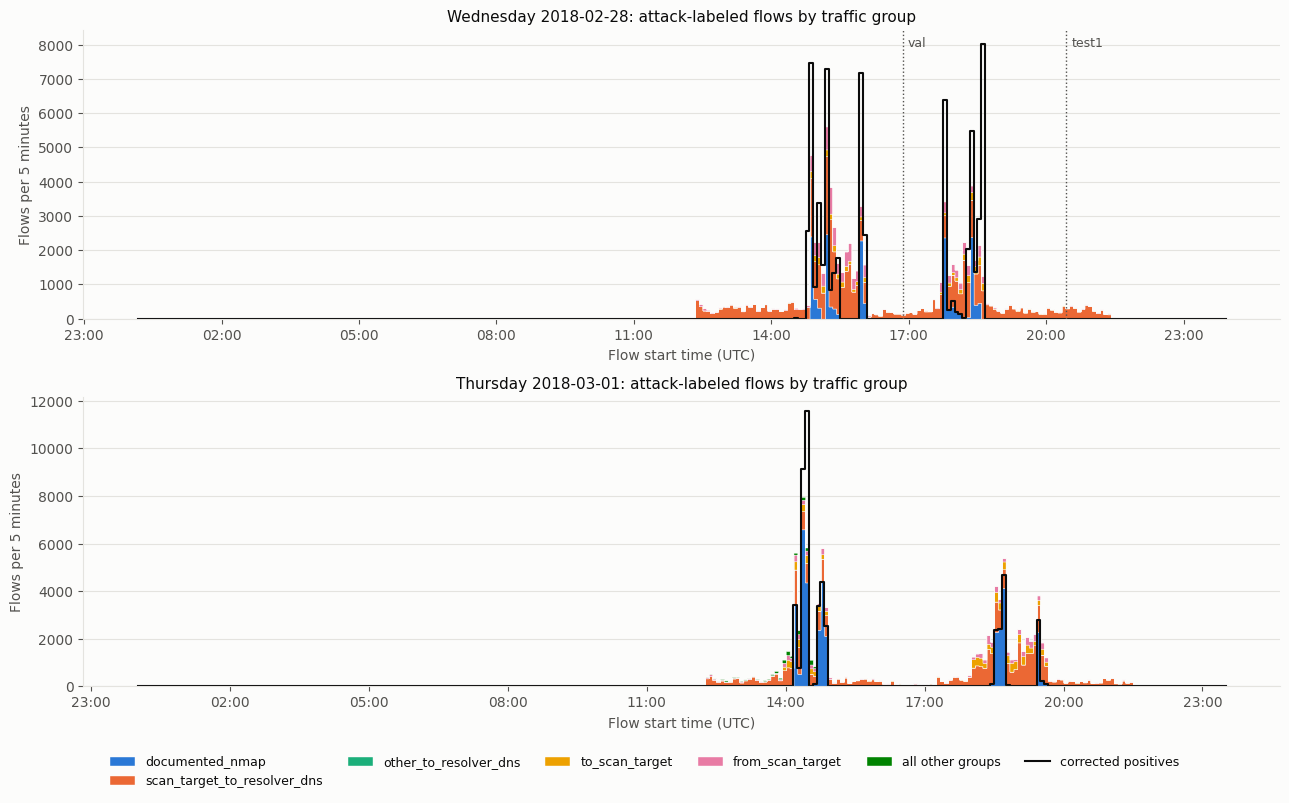

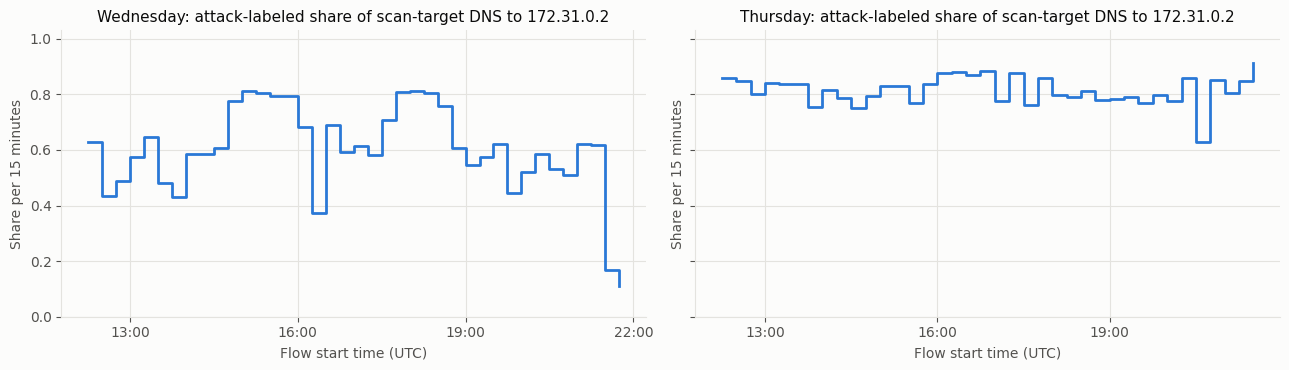

,split,flow_group,flows,native_positives,baseline_purity,purity_time_5min,purity_source,purity_destination,purity_source_time,purity_destination_time,purity_pair_time,purity_pair_port_time
0,train,documented_nmap,36685,9317,0.7460,0.7527,0.7460,0.9276,0.7527,0.9399,0.9399,0.9990
1,train,scan_target_to_resolver_dns,44837,30385,0.6777,0.7135,0.7584,0.6777,0.8195,0.7135,0.8195,0.8195
2,train,to_scan_target,9352,2483,0.7345,0.7448,0.8585,0.8291,0.9521,0.8482,0.9666,0.9669
3,train,from_scan_target,21499,7379,0.6568,0.6624,0.6826,0.7707,0.7377,0.9097,0.9373,0.9384
4,test1,scan_target_to_resolver_dns,5952,3179,0.5341,0.5835,0.8014,0.5341,0.8107,0.5835,0.8107,0.8107
5,test1,to_scan_target,1814,98,0.9460,0.9460,0.9647,0.9835,0.9658,0.9879,0.9912,0.9912
6,test1,from_scan_target,1578,157,0.9005,0.9062,0.9626,0.9994,0.9658,0.9994,1.0000,1.0000
7,test2,documented_nmap,47984,35439,0.7386,0.7977,0.7386,0.9695,0.7977,0.9811,0.9811,0.9994
8,test2,infected_host_other,3586,1470,0.5901,0.7641,0.5901,0.6344,0.7641,0.8143,0.8143,0.8157
9,test2,scan_target_to_resolver_dns,61783,49316,0.7982,0.7986,0.8202,0.7982,0.8227,0.7986,0.8227,0.8227


107

In [6]:
FIGURE_GROUPS = ['documented_nmap', 'scan_target_to_resolver_dns', 'other_to_resolver_dns',
                 'to_scan_target', 'from_scan_target']
GROUP_COLORS = dict(zip(FIGURE_GROUPS + ['all other groups'], SERIES))

def hour_axis(ax):
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

def labeled_bins(frame, frequency='5min'):
    labeled = frame.loc[frame.native_label.eq(1), ['flow_start', 'flow_group']].copy()
    labeled['group'] = labeled.flow_group.astype(str).where(labeled.flow_group.isin(FIGURE_GROUPS), 'all other groups')
    bins = labeled.groupby([labeled.flow_start.dt.floor(frequency), 'group']).size().unstack(fill_value=0)
    full = pd.date_range(frame.flow_start.min().floor(frequency), frame.flow_start.max().floor(frequency), freq=frequency)
    return bins.reindex(full, fill_value=0).reindex(columns=list(GROUP_COLORS), fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
for ax, day, title in zip(axes, ('wed', 'thu'), ('Wednesday 2018-02-28', 'Thursday 2018-03-01')):
    frame = raw_days[day]
    bins = labeled_bins(frame)
    ax.stackplot(bins.index, bins.T.to_numpy(), labels=bins.columns, colors=[GROUP_COLORS[c] for c in bins.columns],
                 edgecolor=SURFACE, linewidth=0.3, step='post')
    corrected = frame.loc[frame.corrected_label.eq(1)].groupby(frame.flow_start.dt.floor('5min')).size()
    corrected = corrected.reindex(bins.index, fill_value=0)
    ax.step(corrected.index, corrected.to_numpy(), where='post', color=INK, linewidth=1.5, label='corrected positives')
    for tag in ('val', 'test1'):
        if DAY_OF_TAG[tag] == day:
            ax.axvline(contexts[tag]['start'], color=MUTED, linestyle=':', linewidth=1)
            ax.annotate(tag, (contexts[tag]['start'], 1), xycoords=('data', 'axes fraction'), xytext=(4, -12),
                        textcoords='offset points', color=MUTED, fontsize=9)
    ax.set(title=title + ': attack-labeled flows by traffic group', ylabel='Flows per 5 minutes', xlabel='Flow start time (UTC)')
    ax.grid(axis='x', visible=False)
    hour_axis(ax)
fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=6, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, 0.0))
save_figure(fig, 'attack_label_timeline')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, day, title in zip(axes, ('wed', 'thu'), ('Wednesday', 'Thursday')):
    frame = raw_days[day]
    frame = frame.loc[frame.flow_group.eq('scan_target_to_resolver_dns')]
    if len(frame):
        share = frame.groupby(frame.flow_start.dt.floor('15min')).native_label.mean()
        ax.step(share.index, share.to_numpy(), where='post', color=MODEL_COLORS['MLP'])
    ax.set(title=f'{title}: attack-labeled share of scan-target DNS to {RESOLVER}', ylabel='Share per 15 minutes',
           xlabel='Flow start time (UTC)', ylim=(0, 1.03))
    hour_axis(ax)
fig.tight_layout()
save_figure(fig, 'scan_target_dns_label_share')

def label_purity(table, keys):
    grouped = table.groupby(keys, observed=True, sort=False).native_label.agg(['size', 'sum'])
    return float(np.maximum(grouped['sum'], grouped['size'] - grouped['sum']).sum() / grouped['size'].sum()), len(grouped)

PURITY_KEYS = {
    'time_5min': ['time_bin'], 'source': ['src_ip'], 'destination': ['dst_ip'], 'source_time': ['src_ip', 'time_bin'],
    'destination_time': ['dst_ip', 'time_bin'], 'pair_time': ['src_ip', 'dst_ip', 'time_bin'],
    'pair_port_time': ['src_ip', 'dst_ip', 'dst_port', 'time_bin'],
}
purity_rows = []
for tag in ('train', 'test1', 'test2'):
    table = contexts[tag]['table']
    table = table.assign(time_bin=table.flow_start.dt.floor('5min'))
    for group, part in table.groupby('flow_group', observed=True):
        positives = int(part.native_label.sum())
        if positives < MIN_GROUP_POSITIVES:
            continue
        rate = part.native_label.mean()
        row = dict(split=tag, flow_group=group, flows=len(part), native_positives=positives, baseline_purity=max(rate, 1 - rate))
        for name, keys in PURITY_KEYS.items():
            purity, cells = label_purity(part, keys)
            row[f'purity_{name}'] = purity
            row[f'flows_per_key_{name}'] = len(part) / cells
        purity_rows.append(row)
label_purity_table = pd.DataFrame(purity_rows)
label_purity_table.to_csv(ANALYSIS_RUN / 'label_context_purity.csv', index=False)
display(label_purity_table[['split', 'flow_group', 'flows', 'native_positives', 'baseline_purity'] +
                           [f'purity_{name}' for name in PURITY_KEYS]].round(4))
for tag, ctx in contexts.items():
    ctx['table'].drop(columns='label').to_parquet(ANALYSIS_RUN / f'flow_attribution_{tag}.parquet', index=False)
del raw_days
gc.collect()

## 7. Verify the eight-model inventory

The inventory, hash checks, and score alignment are the same as in `paper_eight_models_postanalysis_colab.ipynb`. Every cached score must also reproduce its recorded AP on the original labels, which proves that the join did not reorder flows.

In [7]:
catalog, selection_tables = {}, []
recorded_tables = []
for origin, root, manifest, definitions in [
    ('factorial', FACTORIAL_ROOT, factorial_manifest, factorial_manifest['cells']),
    ('baseline_retraining', BASELINE_ROOT, baseline_manifest, baseline_manifest['models']),
    ('temporal_mlp', TEMPORAL_ROOT, temporal_manifest, temporal_manifest['models']),
]:
    definitions = {name: definition for name, definition in definitions.items() if name in PAPER_MODELS}
    for name, definition in definitions.items():
        assert name not in catalog
        folder = name if origin == 'factorial' else definition['folder']
        catalog[name] = dict(origin=origin, root=root, folder=folder, manifest_sha256=json_digest(manifest))
    champions_path = root / 'champions_by_validation.csv'
    champions = read_csv(champions_path)
    assert champions['Architecture'].is_unique
    for _, row in champions.iterrows():
        if row['Architecture'] in definitions:
            assert row['selection_status'] == 'selected', row['Architecture']
            catalog[row['Architecture']]['champion_seed'] = int(row['Seed'])
    selection_tables.append(champions.loc[champions['Architecture'].isin(definitions)].assign(origin=origin))
    track(champions_path, f'{origin}_validation_selection')
    frozen_path = root / 'frozen_selection.json'
    if frozen_path.exists():
        frozen = json.loads(frozen_path.read_text())
        assert frozen['champions_sha256'] == sha256_file(champions_path)
        for name in definitions:
            assert int(frozen['champion_seeds'][name]) == catalog[name]['champion_seed']
        track(frozen_path, f'{origin}_frozen_selection')
    for tag, filename in [('test1', 'test1_all_seeds.csv'), ('test2', 'test2_champions.csv')]:
        path = root / filename
        frame = read_csv(path)
        recorded_tables.append(frame.loc[frame['model'].isin(definitions)].assign(origin=origin))
        track(path, f'{origin}_{tag}_metrics')
assert set(catalog) == set(PAPER_MODELS), 'Missing requested model in manifests'
catalog = {name: catalog[name] for name in PAPER_MODELS}
recorded = pd.concat(recorded_tables, ignore_index=True)
assert not recorded.duplicated(['model', 'seed', 'split']).any()
verified_records = {}

def aligned_array(flow_index, probabilities, tag):
    ctx = contexts[tag]
    ids, p = np.asarray(flow_index), np.asarray(probabilities)
    assert len(ids) == len(p) == ctx['n']
    assert np.issubdtype(ids.dtype, np.integer)
    assert np.array_equal(np.sort(ids), np.arange(ctx['n']))
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    aligned = np.empty(ctx['n'], dtype=p.dtype)
    aligned[ids] = p
    return aligned

def score_path(name, seed, tag):
    spec = catalog[name]
    return spec['root'] / spec['folder'] / f'seed_{int(seed)}' / f'{tag}_scores.npz'

def neural_score(name, seed, tag):
    spec = catalog[name]
    path = score_path(name, seed, tag)
    assert path.is_file(), f'Missing completed score cache: {path}; rerun its evaluation section'
    folder, key = path.parent, (name, int(seed))
    if key not in verified_records:
        record = json.loads((folder / 'record.json').read_text())
        assert record['status'] == 'complete' and int(record['seed']) == int(seed)
        assert record.get('cell', record.get('model')) == name
        assert record['manifest_sha256'] == spec['manifest_sha256']
        if VERIFY_CHECKPOINT_HASHES:
            assert sha256_file(folder / 'checkpoint.pth') == record['checkpoint_sha256']
        verified_records[key] = record
        track(folder / 'record.json', 'training_record')
    record = verified_records[key]
    with np.load(path, allow_pickle=False) as saved:
        metadata = json.loads(str(saved['metadata'].item()))
        assert metadata['model'] == name and int(metadata['seed']) == int(seed)
        assert metadata['split'] == tag and metadata['manifest_sha256'] == spec['manifest_sha256']
        assert metadata['checkpoint_sha256'] == record['checkpoint_sha256']
        assert float(metadata['threshold']) == float(record['threshold'])
        assert metadata['alignment_sha256'] == contexts[tag]['alignment_sha256']
        assert metadata['dataset_sha256'] == contexts[tag]['dataset_sha256']
        probabilities = aligned_array(saved['flow_index'], saved['probabilities'], tag)
    track(path, f'{tag}_scores')
    return probabilities, float(record['threshold'])

def check_recorded_ap(name, seed, tag, p):
    row = recorded.loc[recorded.model.eq(name) & recorded.seed.eq(int(seed)) & recorded.split.eq(tag)]
    assert len(row) == 1 and row.iloc[0]['status'] == 'complete', (name, seed, tag)
    ap = average_precision_score(contexts[tag]['y_native'], p)
    assert np.isclose(float(row.iloc[0]['AUC-PR']), ap, atol=1e-7, rtol=1e-6), (name, seed, tag, ap)

def metrics(y, p, threshold):
    alert = p > threshold
    positives, negatives = int(y.sum()), int((y == 0).sum())
    tp, fp = int(np.sum(alert & (y == 1))), int(np.sum(alert & (y == 0)))
    fn, tn = positives - tp, negatives - fp
    return dict(flows=len(y), positives=positives, prevalence=positives / len(y) if len(y) else np.nan,
        AP=float(average_precision_score(y, p)) if positives else np.nan,
        AUC_ROC=float(roc_auc_score(y, p)) if positives and negatives else np.nan,
        Precision=tp / (tp + fp) if tp + fp else 0.0, Recall=tp / positives if positives else np.nan,
        F1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
        FPR=fp / negatives if negatives else np.nan, TP=tp, FP=fp, FN=fn, TN=tn, alerts=tp + fp)

def max_f1_threshold(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    # sklearn thresholds use >=; alerts here use >, so step just below the selected score.
    return float(np.nextafter(thresholds[int(np.argmax(f1))], -np.inf))

display(pd.concat(selection_tables, ignore_index=True).reindex(columns=['Architecture', 'origin', 'Seed', 'selection_status', 'Val_AP']))

,Architecture,origin,Seed,selection_status,Val_AP
0,M0_P0,factorial,2024,selected,0.402332
1,M0_P1,factorial,123,selected,0.393351
2,M1_P0,factorial,2024,selected,0.741069
3,M1_P1,factorial,2024,selected,0.784015
4,MLP,baseline_retraining,777,selected,0.225139
5,E-GraphSAGE,baseline_retraining,2024,selected,0.397037
6,Global traffic MLP-GRU,temporal_mlp,42,selected,0.210571
7,Host history MLP-GRU,temporal_mlp,2024,selected,0.798113


## 8. Test 2: original versus corrected labels

Each champion is scored on both label sets. `validation_native_max_F1` is the frozen threshold from the original protocol. `validation_corrected_max_F1` is a sensitivity point: it re-selects the threshold on validation with corrected labels and never uses Test 2. `only_infected_host` asks how well a model ranks documented activity among that host's own flows. `excluding_infected_host` repeats the earlier source exclusion on original labels for reference; no corrected positive remains in that cohort.

Scored Test 2: MLP | seed 777
Scored Test 2: Global traffic MLP-GRU | seed 42
Scored Test 2: Host history MLP-GRU | seed 2024
Scored Test 2: E-GraphSAGE | seed 2024
Scored Test 2: M0_P0 | seed 2024
Scored Test 2: M0_P1 | seed 123
Scored Test 2: M1_P0 | seed 2024
Scored Test 2: M1_P1 | seed 2024


,model,labels,operating_point,positives,AP,AUC_ROC,Precision,Recall,F1,FPR,TP,FP
3,MLP,corrected,validation_corrected_max_F1,48026,0.64464,0.72796,0.88416,0.69273,0.77682,0.00209,33269,4359
15,Global traffic MLP-GRU,corrected,validation_corrected_max_F1,48026,0.62238,0.69886,0.88783,0.65887,0.75640,0.00191,31643,3998
39,E-GraphSAGE,corrected,validation_corrected_max_F1,48026,0.59379,0.74780,0.90715,0.58652,0.71242,0.00138,28168,2883
63,M0_P1,corrected,validation_corrected_max_F1,48026,0.49290,0.71408,0.95832,0.39547,0.55989,0.00040,18993,826
51,M0_P0,corrected,validation_corrected_max_F1,48026,0.45592,0.71822,0.27972,0.48844,0.35572,0.02893,23458,60405
87,M1_P1,corrected,validation_corrected_max_F1,48026,0.23529,0.75526,0.28171,0.07935,0.12383,0.00465,3811,9717
27,Host history MLP-GRU,corrected,validation_corrected_max_F1,48026,0.10867,0.54543,0.23299,0.19973,0.21508,0.01512,9592,31577
75,M1_P0,corrected,validation_corrected_max_F1,48026,0.07127,0.63705,0.11316,0.38664,0.17508,0.06970,18569,145524
2,MLP,corrected,validation_native_max_F1,48026,0.64464,0.72796,0.87502,0.69306,0.77349,0.00228,33285,4754
14,Global traffic MLP-GRU,corrected,validation_native_max_F1,48026,0.62238,0.69886,0.88950,0.65871,0.75690,0.00188,31635,3930


,model,labels,operating_point,positives,AP,AUC_ROC,Precision,Recall,F1,FPR,TP,FP,prevalence
6,MLP,corrected,validation_native_max_F1,48026,0.97882,0.71602,1.00000,0.69306,0.81871,0.00000,33285,0,0.93029
18,Global traffic MLP-GRU,corrected,validation_native_max_F1,48026,0.97382,0.68181,0.99997,0.65871,0.79423,0.00028,31635,1,0.93029
30,Host history MLP-GRU,corrected,validation_native_max_F1,48026,0.95831,0.54521,1.00000,0.24803,0.39748,0.00000,11912,0,0.93029
42,E-GraphSAGE,corrected,validation_native_max_F1,48026,0.97819,0.72692,0.99996,0.58847,0.74092,0.00028,28262,1,0.93029
54,M0_P0,corrected,validation_native_max_F1,48026,0.97687,0.71279,1.00000,0.40872,0.58027,0.00000,19629,0,0.93029
66,M0_P1,corrected,validation_native_max_F1,48026,0.97405,0.68895,1.00000,0.40180,0.57327,0.00000,19297,0,0.93029
78,M1_P0,corrected,validation_native_max_F1,48026,0.96303,0.58799,1.00000,0.33461,0.50144,0.00000,16070,0,0.93029
90,M1_P1,corrected,validation_native_max_F1,48026,0.97925,0.73769,0.99986,0.44062,0.61168,0.00083,21161,3,0.93029


model                        MLP  Global traffic MLP-GRU  \
labels    budget_fraction                                  
corrected 0.0001             213                      79   
          0.0005             970                     670   
          0.0010            1810                    1639   
          0.0025            3386                    4818   
          0.0050            8717                   10092   
          0.0100           19397                   20656   
          0.0200           33298                   32004   
          0.0500           33402                   32004   
          0.1000           33405                   32004   
native    0.0001             213                      79   
          0.0005             968                     814   
          0.0010            1805                    1783   
          0.0025            3381                    4962   
          0.0050            8712                   10238   
          0.0100           19392                   20810   
          0.0200           33575                   32469   
          0.0500           36961                   36838   
          0.1000           43536                   44768   

model                      Host history MLP-GRU  E-GraphSAGE  M0_P0  M0_P1  \
labels    budget_fraction                                                    
corrected 0.0001                            182          210     71    213   
          0.0005                            312         1027    696   1066   
          0.0010                            403         1855   1764   2134   
          0.0025                           1294         4698   4826   5338   
          0.0050                           4137         9928  10084  10678   
          0.0100                           5360        20290  17917  19097   
          0.0200                           9608        28239  18445  19248   
          0.0500                          13641        33501  33622  32632   
          0.1000                          21275        34677  33837  32649   
native    0.0001                            208          210    149    213   
          0.0005                            920         1024    966   1066   
          0.0010                           1831         1859   2034   2134   
          0.0025                           4638         4710   5171   5338   
          0.0050                           9617         9961  10484  10678   
          0.0100                          18763        20412  20246  20347   
          0.0200                          35502        33133  31983  33039   
          0.0500                          70867        53705  53723  52882   
          0.1000                          87935        68335  59283  58162   

model                      M1_P0   M1_P1  
labels    budget_fraction                 
corrected 0.0001             208     212  
          0.0005             454    1063  
          0.0010             570    2117  
          0.0025             747    3509  
          0.0050             931    3732  
          0.0100            1338    4301  
          0.0200            1654   10776  
          0.0500           10273   21148  
          0.1000           20955   35314  
native    0.0001             210     212  
          0.0005             959    1061  
          0.0010            1888    2119  
          0.0025            4633    5029  
          0.0050            9253    9570  
          0.0100           18281   18747  
          0.0200           33976   37224  
          0.0500           68974   77031  
          0.1000           87573  100876

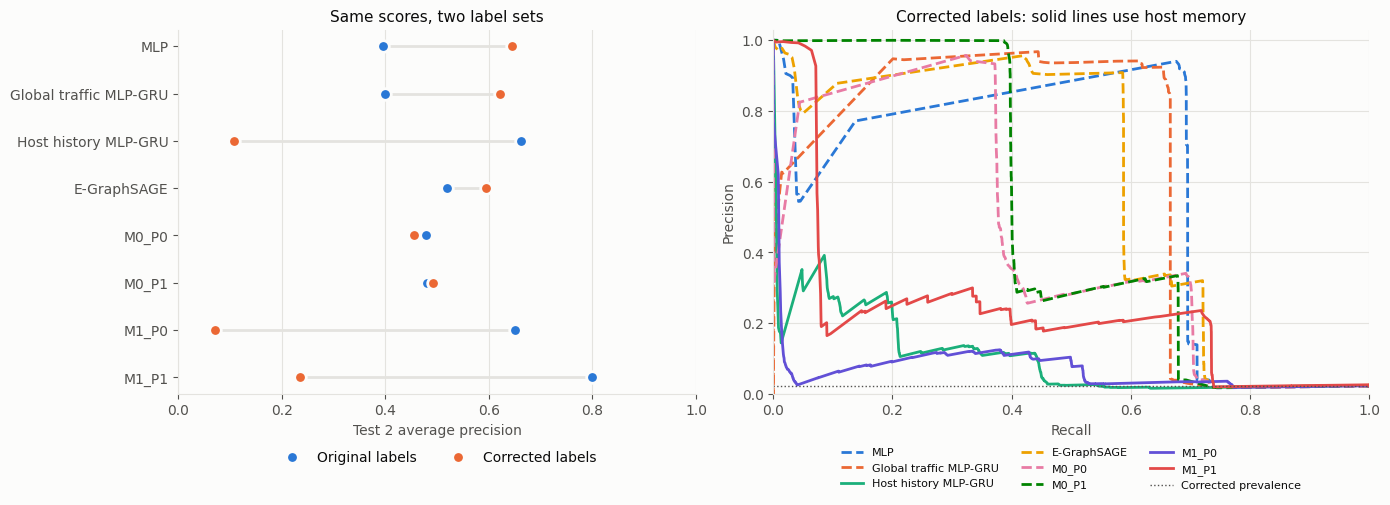

In [8]:
ctx = contexts['test2']
table = ctx['table']
infected_mask = table.src_ip.eq(INFECTED_HOST['thu']).to_numpy()
cohorts = {'full': np.ones(ctx['n'], dtype=bool), 'only_infected_host': infected_mask, 'excluding_infected_host': ~infected_mask}
test2_predictions, metric_rows, budget_rows = {}, [], []
pr_curves = {}
for name, spec in catalog.items():
    seed = spec['champion_seed']
    p, threshold = neural_score(name, seed, 'test2')
    check_recorded_ap(name, seed, 'test2', p)
    val_p, _ = neural_score(name, seed, 'val')
    val_y = contexts['val']['y_corrected']
    corrected_threshold = max_f1_threshold(val_y, val_p) if val_y.any() else None
    test2_predictions[name] = dict(probabilities=p, threshold=threshold, corrected_threshold=corrected_threshold, seed=seed)
    points = {'validation_native_max_F1': threshold}
    if corrected_threshold is not None:
        points['validation_corrected_max_F1'] = corrected_threshold
    for cohort, mask in cohorts.items():
        for labels, y in (('native', ctx['y_native']), ('corrected', ctx['y_corrected'])):
            for point, value in points.items():
                metric_rows.append(dict(model=name, seed=seed, labels=labels, cohort=cohort, operating_point=point,
                                        threshold=value, **metrics(y[mask], p[mask], value)))
    ranked = np.argsort(-p, kind='stable')
    for labels, y in (('native', ctx['y_native']), ('corrected', ctx['y_corrected'])):
        ordered = y[ranked]
        cumulative = np.cumsum(ordered, dtype=np.int64)
        total = int(y.sum())
        for fraction in BUDGET_FRACTIONS:
            k = max(1, int(np.floor(fraction * ctx['n'])))
            tp = int(cumulative[k - 1])
            budget_rows.append(dict(model=name, seed=seed, labels=labels, budget_fraction=fraction, budget_alerts=k,
                                    TP=tp, FP=k - tp, Precision=tp / k, Recall=tp / total if total else np.nan))
    if ctx['y_corrected'].any():
        precision, recall, _ = precision_recall_curve(ctx['y_corrected'], p)
        keep = np.unique(np.r_[np.arange(0, len(recall), max(1, len(recall) // PR_GRID_POINTS)), len(recall) - 1])
        pr_curves[name] = (recall[keep], precision[keep])
    print('Scored Test 2:', name, '| seed', seed)
test2_metrics = pd.DataFrame(metric_rows)
test2_budgets = pd.DataFrame(budget_rows)
test2_metrics.to_csv(ANALYSIS_RUN / 'test2_metrics_by_labels.csv', index=False)
test2_budgets.to_csv(ANALYSIS_RUN / 'test2_alert_budgets_by_labels.csv', index=False)
shown = ['model', 'labels', 'operating_point', 'positives', 'AP', 'AUC_ROC', 'Precision', 'Recall', 'F1', 'FPR', 'TP', 'FP']
display(test2_metrics.loc[test2_metrics.cohort.eq('full'), shown].sort_values(['labels', 'operating_point', 'AP'], ascending=[True, True, False]).round(5))
display(test2_metrics.loc[test2_metrics.cohort.eq('only_infected_host') & test2_metrics.labels.eq('corrected')
                          & test2_metrics.operating_point.eq('validation_native_max_F1'), shown + ['prevalence']].round(5))
display(test2_budgets.pivot_table(index=['labels', 'budget_fraction'], columns='model', values='TP')[PAPER_MODELS].astype(int))

frozen = test2_metrics.loc[test2_metrics.cohort.eq('full') & test2_metrics.operating_point.eq('validation_native_max_F1')]
ap_table = frozen.pivot(index='model', columns='labels', values='AP').reindex(PAPER_MODELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
positions = np.arange(len(ap_table))
axes[0].hlines(positions, ap_table.native, ap_table.corrected, color=RULE, linewidth=2, zorder=1)
axes[0].scatter(ap_table.native, positions, s=70, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=2, label='Original labels')
axes[0].scatter(ap_table.corrected, positions, s=70, color=SERIES[1], edgecolor=SURFACE, linewidth=2, zorder=2, label='Corrected labels')
axes[0].set_yticks(positions, ap_table.index)
axes[0].invert_yaxis()
axes[0].set(xlabel='Test 2 average precision', xlim=(0, 1), title='Same scores, two label sets')
axes[0].grid(axis='y', visible=False)
axes[0].legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.12))
for name, (recall, precision) in pr_curves.items():
    axes[1].plot(recall, precision, color=MODEL_COLORS[name], linestyle='-' if name in MEMORY_MODELS else '--', label=name)
axes[1].axhline(ctx['y_corrected'].mean(), color=MUTED, linestyle=':', linewidth=1, label='Corrected prevalence')
axes[1].set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03), title='Corrected labels: solid lines use host memory')
axes[1].legend(fontsize=8, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
save_figure(fig, 'test2_native_vs_corrected')

## 9. What does each model alert on?

These tables use the frozen thresholds. Alert rate by group shows where a model spends its alerts. Recall by source IP shows which attack-labeled sources each model reaches; a detected source means at least one true-positive flow, which is a weak criterion for sources with few flows, so sources are grouped by flow support. Campaign coverage reports flow recall per documented stage, per scan target, and per scan window; delay is retrospective, measured in flow-start windows, and is not online latency. The per-host table checks whether a model separates attack-labeled from other flows of the same host, or flags the host as a whole. False-alert concentration is reported on both label sets because the historical result is not valid for these models.

Alert rate on attack-labeled flows


model,MLP,Global traffic MLP-GRU,Host history MLP-GRU,E-GraphSAGE,M0_P0,M0_P1,M1_P0,M1_P1
flow_group,,,,,,,,
documented_nmap,0.9390,0.8927,0.3357,0.7971,0.5537,0.5445,0.4530,0.5965
documented_dropbox,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
documented_victim_attacker,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
attempted_artifact,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
attacker_to_infected_host,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
infected_host_other,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0014
scan_target_to_resolver_dns,0.0000,0.0000,0.9915,0.2940,0.3367,0.3006,0.9951,0.9688
to_scan_target,0.0221,0.0269,0.7344,0.0511,0.0757,0.0506,0.8995,0.6733
from_scan_target,0.0000,0.0000,0.1009,0.0679,0.0654,0.0628,0.8071,0.3269


Alert rate on flows not labeled as attack


model,MLP,Global traffic MLP-GRU,Host history MLP-GRU,E-GraphSAGE,M0_P0,M0_P1,M1_P0,M1_P1
flow_group,,,,,,,,
documented_nmap,0.0006,0.0000,0.0011,0.0010,0.0006,0.0000,0.0012,0.0016
documented_dropbox,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
attempted_artifact,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
infected_host_other,0.0000,0.0005,0.0000,0.0005,0.0000,0.0000,0.0000,0.0005
scan_target_to_resolver_dns,0.0000,0.0000,0.8856,0.2065,0.2425,0.2115,0.8887,0.8546
other_to_resolver_dns,0.0000,0.0000,0.0022,0.0311,0.0227,0.0119,0.0004,0.0001
to_scan_target,0.0074,0.0155,0.1061,0.0144,0.0240,0.0129,0.4763,0.2277
from_scan_target,0.0000,0.0003,0.0113,0.0056,0.0056,0.0055,0.6304,0.1479
other_traffic,0.0036,0.0028,0.0156,0.0019,0.0019,0.0007,0.0219,0.0168


Attack-labeled sources with at least one true positive, by role and flow support


model                                                 MLP  \
role                support sources native_positives        
documented attacker 10-49   1       13                  0   
external            1       25      25                  0   
                    2-9     304     847                43   
                    10-49   30      690                 4   
                    50+     9       7879                1   
infected host       50+     1       36934               1   
scan target         50+     10      57437               0   

model                                                 Global traffic MLP-GRU  \
role                support sources native_positives                           
documented attacker 10-49   1       13                                     0   
external            1       25      25                                     0   
                    2-9     304     847                                   66   
                    10-49   30      690                                    4   
                    50+     9       7879                                   1   
infected host       50+     1       36934                                  1   
scan target         50+     10      57437                                  0   

model                                                 Host history MLP-GRU  \
role                support sources native_positives                         
documented attacker 10-49   1       13                                   0   
external            1       25      25                                   3   
                    2-9     304     847                                  8   
                    10-49   30      690                                  4   
                    50+     9       7879                                 8   
infected host       50+     1       36934                                1   
scan target         50+     10      57437                               10   

model                                                 E-GraphSAGE  M0_P0  \
role                support sources native_positives                       
documented attacker 10-49   1       13                          0      0   
external            1       25      25                          1      0   
                    2-9     304     847                        40     90   
                    10-49   30      690                         5     11   
                    50+     9       7879                        5      1   
infected host       50+     1       36934                       1      1   
scan target         50+     10      57437                      10     10   

model                                                 M0_P1  M1_P0  M1_P1  
role                support sources native_positives                       
documented attacker 10-49   1       13                    0      0      0  
external            1       25      25                    0      6      3  
                    2-9     304     847                  60     75     57  
                    10-49   30      690                   4     25     23  
                    50+     9       7879                  1      9      9  
infected host       50+     1       36934                 1      1      1  
scan target         50+     10      57437                10     10      9

Flow recall by role and flow support


model                           MLP  Global traffic MLP-GRU  \
role                support                                   
documented attacker 10-49    0.0000                  0.0000   
external            1        0.0000                  0.0000   
                    2-9      0.1488                  0.2031   
                    10-49    0.0174                  0.0174   
                    50+      0.0096                  0.0096   
infected host       50+      0.9010                  0.8565   
scan target         50+      0.0000                  0.0000   

model                        Host history MLP-GRU  E-GraphSAGE   M0_P0  \
role                support                                              
documented attacker 10-49                  0.0000       0.0000  0.0000   
external            1                      0.1200       0.0400  0.0000   
                    2-9                    0.0189       0.1299  0.2928   
                    10-49                  0.0696       0.0188  0.2203   
                    50+                    0.8514       0.0143  0.0096   
infected host       50+                    0.3221       0.7649  0.5313   
scan target         50+                    0.8707       0.2661  0.3024   

model                         M0_P1   M1_P0   M1_P1  
role                support                          
documented attacker 10-49    0.0000  0.0000  0.0000  
external            1        0.0000  0.2400  0.1200  
                    2-9      0.1842  0.2621  0.1783  
                    10-49    0.0203  0.7551  0.4333  
                    50+      0.0096  0.9656  0.7309  
infected host       50+      0.5225  0.4347  0.5725  
scan target         50+      0.2708  0.9696  0.8813

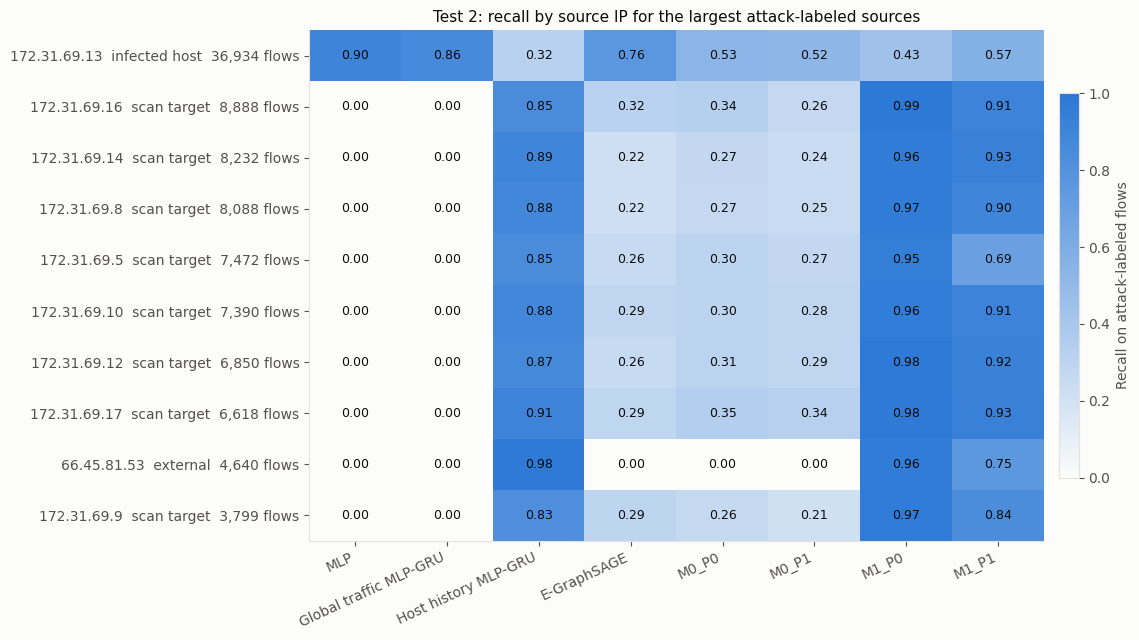

model,MLP,Global traffic MLP-GRU,Host history MLP-GRU,E-GraphSAGE,M0_P0,M0_P1,M1_P0,M1_P1
stage,,,,,,,,
confirmed_dropbox_download,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.000
confirmed_nmap_portscan,0.6937,0.6593,0.2482,0.589,0.4091,0.4022,0.3349,0.441
confirmed_victim_attacker_communication,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.000


,model,scan_flows,scan_recall,scan_windows,scan_windows_detected,targets_detected,targets,first_detection_minutes,scan_window_coverage
0,MLP,47984,0.6937,107,91,20,21,0.8891,0.8505
1,Global traffic MLP-GRU,47984,0.6593,107,48,20,21,0.8891,0.4486
2,Host history MLP-GRU,47984,0.2482,107,64,13,21,13.6692,0.5981
3,E-GraphSAGE,47984,0.5890,107,88,20,21,0.8891,0.8224
4,M0_P0,47984,0.4091,107,52,13,21,27.8210,0.4860
5,M0_P1,47984,0.4022,107,68,20,21,0.8891,0.6355
6,M1_P0,47984,0.3349,107,57,13,21,30.2571,0.5327
7,M1_P1,47984,0.4410,107,96,21,21,0.8143,0.8972


,alert_rate_labeled,alert_rate_other,AP,prevalence,AP_lift
model,,,,,
MLP,0.0901,0.0000,0.8424,0.715,0.1274
Global traffic MLP-GRU,0.0857,0.0001,0.8252,0.715,0.1102
Host history MLP-GRU,0.8253,0.3776,0.8545,0.715,0.1395
E-GraphSAGE,0.2906,0.0813,0.8523,0.715,0.1373
M0_P0,0.2927,0.0923,0.8492,0.715,0.1342
M0_P1,0.2669,0.0817,0.8499,0.715,0.1349
M1_P0,0.9153,0.6668,0.8509,0.715,0.1359
M1_P1,0.8358,0.4260,0.8567,0.715,0.1417


,model,labels,false_alerts,top1_ip,top1_share,top5_share,top10_share
0,MLP,native,4547,219.135.224.15,0.8795,0.9213,0.9301
1,MLP,corrected,4754,219.135.224.15,0.8412,0.8934,0.9043
2,Global traffic MLP-GRU,native,3670,172.31.66.82,0.0452,0.1905,0.3207
3,Global traffic MLP-GRU,corrected,3930,172.31.66.82,0.0422,0.1779,0.3003
4,Host history MLP-GRU,native,33453,219.135.224.15,0.5869,0.7797,0.9345
5,Host history MLP-GRU,corrected,90222,219.135.224.15,0.2176,0.6025,0.9466
6,E-GraphSAGE,native,27740,219.135.224.15,0.0414,0.1320,0.2105
7,E-GraphSAGE,corrected,43249,172.31.69.16,0.0748,0.2842,0.4563
8,M0_P0,native,22137,219.135.224.15,0.0251,0.1067,0.1970
9,M0_P0,corrected,39977,172.31.69.16,0.0850,0.3470,0.5303


In [9]:
ctx = contexts['test2']
table = ctx['table']
breakdown_parts, stage_rows, target_rows, host_rows, fp_rows, fp_summary_rows = [], [], [], [], [], []
documented = table.correction_rule.isin(['confirmed_nmap_portscan', 'confirmed_dropbox_download', 'confirmed_victim_attacker_communication']).to_numpy()
scan_mask = table.correction_rule.eq('confirmed_nmap_portscan').to_numpy()
scan_windows = table.window_id.to_numpy()[scan_mask]
scan_start = table.loc[scan_mask, 'flow_start'].min() if scan_mask.any() else pd.NaT
hosts = source_tables['test2'].ip.head(TOP_SOURCES_TO_INSPECT).tolist()
host_positions = {ip: np.flatnonzero(table.src_ip.eq(ip).to_numpy()) for ip in hosts}
src_codes = table.src_ip.cat.remove_unused_categories()
src_names = np.asarray(src_codes.cat.categories)
src_codes = src_codes.cat.codes.to_numpy()
source_index = source_tables['test2'][['ip', 'role', 'native_positives', 'kept_by_rules']].copy()
source_index['code'] = source_index.ip.map({ip: code for code, ip in enumerate(src_names)})
source_index['support'] = pd.cut(source_index.native_positives, bins=[0, 1, 9, 49, np.inf], labels=['1', '2-9', '10-49', '50+'])
source_parts = []
for name, result in test2_predictions.items():
    p, alert = result['probabilities'], result['probabilities'] > result['threshold']
    parts = table[['flow_group', 'native_label', 'corrected_label']].assign(alert=alert)
    part = parts.groupby(['flow_group', 'native_label', 'corrected_label'], observed=True).alert.agg(flows='size', alerts='sum').reset_index()
    breakdown_parts.append(part.assign(model=name, seed=result['seed']))
    true_positives = np.bincount(src_codes, weights=alert & (ctx['y_native'] == 1), minlength=len(src_names)).astype(np.int64)
    source_parts.append(source_index.assign(model=name, detected_flows=true_positives[source_index.code.to_numpy()]))
    for rule, frame in table.loc[documented].groupby('correction_rule', observed=True):
        hits = alert[frame.index.to_numpy()]
        stage_rows.append(dict(model=name, stage=rule, flows=len(frame), detected_flows=int(hits.sum()), flow_recall=float(hits.mean()),
                               detected_by_original_label=int(np.sum(hits & (frame.native_label.to_numpy() == 1)))))
    if scan_mask.any():
        scan_hits = alert[scan_mask]
        hit_times = table.flow_start.to_numpy()[scan_mask][scan_hits]
        target_frame = pd.DataFrame(dict(target=table.dst_ip.astype(str).to_numpy()[scan_mask], hit=scan_hits))
        for target, frame in target_frame.groupby('target'):
            target_rows.append(dict(model=name, target=target, flows=len(frame), flow_recall=float(frame.hit.mean())))
        coverage = dict(model=name, scan_flows=int(scan_mask.sum()), scan_recall=float(scan_hits.mean()),
            scan_windows=int(np.unique(scan_windows).size), scan_windows_detected=int(np.unique(scan_windows[scan_hits]).size),
            targets_detected=int(target_frame.loc[target_frame.hit, 'target'].nunique()), targets=int(target_frame.target.nunique()),
            first_detection_minutes=float((pd.Timestamp(hit_times.min()) - scan_start).total_seconds() / 60) if len(hit_times) else np.nan)
        coverage['scan_window_coverage'] = coverage['scan_windows_detected'] / coverage['scan_windows']
        result['scan_coverage'] = coverage
    for ip, positions in host_positions.items():
        y, q = ctx['y_native'][positions], p[positions]
        host_alert = q > result['threshold']
        host_rows.append(dict(model=name, ip=ip, flows=len(y), native_positives=int(y.sum()), prevalence=float(y.mean()),
            alert_rate_labeled=float(host_alert[y == 1].mean()) if y.any() else np.nan,
            alert_rate_other=float(host_alert[y == 0].mean()) if (y == 0).any() else np.nan,
            AP=float(average_precision_score(y, q)) if y.any() and (y == 0).any() else np.nan))
    for labels, y in (('native', ctx['y_native']), ('corrected', ctx['y_corrected'])):
        fp = np.bincount(src_codes, weights=alert & (y == 0), minlength=len(src_names)).astype(np.int64)
        order = np.argsort(-fp, kind='stable')
        total = int(fp.sum())
        fp_summary_rows.append(dict(model=name, labels=labels, false_alerts=total, top1_ip=src_names[order[0]],
            top1_share=fp[order[0]] / total if total else np.nan,
            top5_share=fp[order[:5]].sum() / total if total else np.nan,
            top10_share=fp[order[:10]].sum() / total if total else np.nan))
        for rank, code_value in enumerate(order[:20], start=1):
            ip = str(src_names[code_value])
            fp_rows.append(dict(model=name, labels=labels, rank=rank, ip=ip, role=ip_role(ip, 'thu'), false_alerts=int(fp[code_value]),
                                share=fp[code_value] / total if total else np.nan))
alert_breakdown = pd.concat(breakdown_parts, ignore_index=True)
alert_breakdown['alert_rate'] = alert_breakdown.alerts / alert_breakdown.flows
source_recall = pd.concat(source_parts, ignore_index=True).drop(columns='code')
source_recall['flow_recall'] = source_recall.detected_flows / source_recall.native_positives
source_detection = source_recall.groupby(['model', 'role', 'support'], observed=True, sort=False).agg(
    sources=('ip', 'size'), sources_detected=('detected_flows', lambda values: int((values > 0).sum())),
    native_positives=('native_positives', 'sum'), detected_flows=('detected_flows', 'sum')).reset_index()
source_detection['flow_recall'] = source_detection.detected_flows / source_detection.native_positives
source_recall.to_csv(ANALYSIS_RUN / 'test2_recall_by_source_ip.csv', index=False)
source_detection.to_csv(ANALYSIS_RUN / 'test2_source_detection_by_role.csv', index=False)
stage_recall = pd.DataFrame(stage_rows)
target_recall = pd.DataFrame(target_rows)
scan_coverage = pd.DataFrame([result['scan_coverage'] for result in test2_predictions.values() if 'scan_coverage' in result])
host_alerts = pd.DataFrame(host_rows)
host_alerts['AP_lift'] = host_alerts.AP - host_alerts.prevalence
false_alert_summary, false_alert_sources = pd.DataFrame(fp_summary_rows), pd.DataFrame(fp_rows)
alert_breakdown.to_csv(ANALYSIS_RUN / 'test2_alerts_by_group.csv', index=False)
stage_recall.to_csv(ANALYSIS_RUN / 'test2_documented_stage_recall.csv', index=False)
target_recall.to_csv(ANALYSIS_RUN / 'test2_scan_target_recall.csv', index=False)
scan_coverage.to_csv(ANALYSIS_RUN / 'test2_scan_coverage.csv', index=False)
host_alerts.to_csv(ANALYSIS_RUN / 'test2_within_host_alerts.csv', index=False)
false_alert_summary.to_csv(ANALYSIS_RUN / 'test2_false_alert_concentration.csv', index=False)
false_alert_sources.to_csv(ANALYSIS_RUN / 'test2_false_alert_top_sources.csv', index=False)
for native_label, title in ((1, 'Alert rate on attack-labeled flows'), (0, 'Alert rate on flows not labeled as attack')):
    print(title)
    display(alert_breakdown.loc[alert_breakdown.native_label.eq(native_label)].pivot_table(
        index='flow_group', columns='model', values='alerts', aggfunc='sum', observed=True).div(
        alert_breakdown.loc[alert_breakdown.native_label.eq(native_label)].pivot_table(
        index='flow_group', columns='model', values='flows', aggfunc='sum', observed=True)).reindex(columns=PAPER_MODELS).round(4))

print('Attack-labeled sources with at least one true positive, by role and flow support')
detection_view = source_detection.pivot_table(index=['role', 'support', 'sources', 'native_positives'], columns='model',
    values='sources_detected', observed=True).reindex(columns=PAPER_MODELS).astype(int)
display(detection_view)
print('Flow recall by role and flow support')
display(source_detection.pivot_table(index=['role', 'support'], columns='model', values='flow_recall', observed=True).reindex(columns=PAPER_MODELS).round(4))

top_sources = source_tables['test2'].head(TOP_SOURCES_TO_INSPECT)
recall_matrix = source_recall.pivot(index='ip', columns='model', values='flow_recall').reindex(index=top_sources.ip, columns=PAPER_MODELS)
fig, ax = plt.subplots(figsize=(11.5, 0.45 * len(recall_matrix) + 2))
image = ax.imshow(recall_matrix.to_numpy(), cmap=LinearSegmentedColormap.from_list('recall', [SURFACE, SERIES[0]]), vmin=0, vmax=1, aspect='auto')
ax.set_xticks(np.arange(len(PAPER_MODELS)), PAPER_MODELS, rotation=25, ha='right')
ax.set_yticks(np.arange(len(top_sources)), [f'{row.ip}  {row.role}  {row.native_positives:,} flows' for row in top_sources.itertuples()])
ax.grid(False)
for (row, column), value in np.ndenumerate(recall_matrix.to_numpy()):
    ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=9, color=INK)
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label='Recall on attack-labeled flows')
ax.set_title('Test 2: recall by source IP for the largest attack-labeled sources')
fig.tight_layout()
save_figure(fig, 'test2_recall_by_source_ip')

display(stage_recall.pivot(index='stage', columns='model', values='flow_recall').reindex(columns=PAPER_MODELS).round(4))
display(scan_coverage.round(4))
display(host_alerts.groupby('model', sort=False).agg(alert_rate_labeled=('alert_rate_labeled', 'mean'), alert_rate_other=('alert_rate_other', 'mean'),
    AP=('AP', 'mean'), prevalence=('prevalence', 'mean'), AP_lift=('AP_lift', 'mean')).reindex(PAPER_MODELS).round(4))
display(false_alert_summary.round(4))

## 10. Test 1: all seeds on both label sets

If the rules leave Test 1 without positives, AP on corrected labels is undefined and every alert in the split is a corrected false alert. The table then reports alert volume, which still shows how much each model reacts to traffic with no documented attack.

In [10]:
ctx = contexts['test1']
test1_rows, test1_groups = [], []
for name in catalog:
    for seed in SEEDS:
        p, threshold = neural_score(name, seed, 'test1')
        check_recorded_ap(name, seed, 'test1', p)
        native, corrected = metrics(ctx['y_native'], p, threshold), metrics(ctx['y_corrected'], p, threshold)
        test1_rows.append(dict(model=name, seed=seed, threshold=threshold, native_AP=native['AP'], corrected_AP=corrected['AP'],
            alerts=native['alerts'], native_TP=native['TP'], native_FP=native['FP'],
            corrected_TP=corrected['TP'], corrected_FP=corrected['FP'], corrected_positives=corrected['positives'],
            alerts_per_100k_flows=1e5 * native['alerts'] / ctx['n']))
        alert = p > threshold
        part = ctx['table'][['flow_group']].assign(alert=alert).groupby('flow_group', observed=True).alert.sum().rename('alerts').reset_index()
        test1_groups.append(part.assign(model=name, seed=seed))
        del p
    gc.collect()
test1_results = pd.DataFrame(test1_rows)
test1_group_alerts = pd.concat(test1_groups, ignore_index=True)
test1_results.to_csv(ANALYSIS_RUN / 'test1_metrics_by_labels.csv', index=False)
test1_group_alerts.to_csv(ANALYSIS_RUN / 'test1_alerts_by_group.csv', index=False)
print('Corrected positives in Test 1:', int(ctx['y_corrected'].sum()))
display(test1_results.groupby('model', sort=False).agg(native_AP_mean=('native_AP', 'mean'), native_AP_sd=('native_AP', 'std'),
    alerts_mean=('alerts', 'mean'), alerts_sd=('alerts', 'std'), native_TP_mean=('native_TP', 'mean'),
    corrected_TP_mean=('corrected_TP', 'mean'), corrected_FP_mean=('corrected_FP', 'mean')).reindex(PAPER_MODELS).round(4))
display(test1_group_alerts.pivot_table(index='flow_group', columns='model', values='alerts', aggfunc='mean', observed=True).reindex(columns=PAPER_MODELS).round(1))

Corrected positives in Test 1: 0


,native_AP_mean,native_AP_sd,alerts_mean,alerts_sd,native_TP_mean,corrected_TP_mean,corrected_FP_mean
model,,,,,,,
MLP,0.0510,0.0078,445.6,289.3066,2.6,0.0,445.6
Global traffic MLP-GRU,0.0471,0.0017,240.0,126.8759,0.4,0.0,240.0
Host history MLP-GRU,0.6988,0.0168,4035.4,565.3422,2623.0,0.0,4035.4
E-GraphSAGE,0.3331,0.0321,6322.0,1764.4459,2302.6,0.0,6322.0
M0_P0,0.3653,0.1575,3396.6,1277.2636,1636.6,0.0,3396.6
M0_P1,0.4193,0.0708,4320.6,1274.1681,2199.4,0.0,4320.6
M1_P0,0.6786,0.0190,5075.6,1100.6740,2655.8,0.0,5075.6
M1_P1,0.6880,0.0208,3952.4,343.4040,2686.6,0.0,3952.4


model,MLP,Global traffic MLP-GRU,Host history MLP-GRU,E-GraphSAGE,M0_P0,M0_P1,M1_P0,M1_P1
flow_group,,,,,,,,
infected_host_other,0.0,0.0,9.2,14.6,0.0,6.8,16.4,9.0
scan_target_to_resolver_dns,2.4,0.0,2946.4,2762.0,1895.8,2566.6,3218.2,3112.6
other_to_resolver_dns,64.2,0.0,677.8,3199.4,1097.2,1518.6,1058.6,321.2
to_scan_target,79.0,78.0,140.2,84.8,91.8,65.6,175.0,173.6
from_scan_target,0.0,0.0,125.4,55.6,41.2,39.8,250.2,166.0
other_traffic,300.0,162.0,136.4,205.6,270.6,123.2,357.2,170.0


## 11. Validation: seed variability and factorial contrasts on both label sets

Validation is the only split with corrected positives and cached scores for all five seeds, so it provides the only seed-paired view of the corrected labels. It is not a test: it drove early stopping, checkpoint selection, and the original thresholds. Test 2 contrasts compare separately selected champions and are not paired by seed.

In [11]:
ctx = contexts['val']
val_rows = []
for name in catalog:
    for seed in SEEDS:
        if not score_path(name, seed, 'val').is_file():
            val_rows.append(dict(model=name, seed=seed, status='unavailable'))
            continue
        p, threshold = neural_score(name, seed, 'val')
        native, corrected = metrics(ctx['y_native'], p, threshold), metrics(ctx['y_corrected'], p, threshold)
        val_rows.append(dict(model=name, seed=seed, status='complete', native_AP=native['AP'], corrected_AP=corrected['AP'],
                             native_F1=native['F1'], corrected_F1=corrected['F1'], corrected_Recall=corrected['Recall']))
        del p
    gc.collect()
val_results = pd.DataFrame(val_rows)
val_results.to_csv(ANALYSIS_RUN / 'validation_metrics_by_labels.csv', index=False)
complete_val = val_results.loc[val_results.status.eq('complete')]
display(complete_val.groupby('model', sort=False).agg(seeds=('seed', 'size'), native_AP_mean=('native_AP', 'mean'), native_AP_sd=('native_AP', 'std'),
    corrected_AP_mean=('corrected_AP', 'mean'), corrected_AP_sd=('corrected_AP', 'std'),
    corrected_Recall_mean=('corrected_Recall', 'mean')).reindex(PAPER_MODELS).round(4))

contrast_weights = {
    'messages_at_M0': {'M0_P1': 1, 'M0_P0': -1}, 'messages_at_M1': {'M1_P1': 1, 'M1_P0': -1},
    'memory_at_P0': {'M1_P0': 1, 'M0_P0': -1}, 'memory_at_P1': {'M1_P1': 1, 'M0_P1': -1},
    'interaction': {'M1_P1': 1, 'M1_P0': -1, 'M0_P1': -1, 'M0_P0': 1},
}
contrast_rows = []
for metric in ('native_AP', 'corrected_AP'):
    for contrast, weights in contrast_weights.items():
        differences = []
        for seed in SEEDS:
            cell = complete_val.loc[complete_val.seed.eq(seed)].set_index('model')[metric]
            if all(name in cell.index for name in weights):
                differences.append(sum(weight * float(cell[name]) for name, weight in weights.items()))
        contrast_rows.append(dict(split='validation_paired_seeds', metric=metric, contrast=contrast, pairs=len(differences),
            mean=np.mean(differences) if differences else np.nan, sd=np.std(differences, ddof=1) if len(differences) > 1 else np.nan,
            minimum=min(differences, default=np.nan), maximum=max(differences, default=np.nan)))
frozen_full = test2_metrics.loc[test2_metrics.cohort.eq('full') & test2_metrics.operating_point.eq('validation_native_max_F1')]
for labels in ('native', 'corrected'):
    cell = frozen_full.loc[frozen_full.labels.eq(labels)].set_index('model').AP
    for contrast, weights in contrast_weights.items():
        contrast_rows.append(dict(split='test2_champions_unpaired', metric=f'{labels}_AP', contrast=contrast, pairs=1,
            mean=sum(weight * float(cell[name]) for name, weight in weights.items())))
factorial_contrasts = pd.DataFrame(contrast_rows)
factorial_contrasts.to_csv(ANALYSIS_RUN / 'factorial_contrasts_by_labels.csv', index=False)
display(factorial_contrasts.round(5))

,seeds,native_AP_mean,native_AP_sd,corrected_AP_mean,corrected_AP_sd,corrected_Recall_mean
model,,,,,,
MLP,5,0.1955,0.0244,0.3328,0.0236,0.3206
Global traffic MLP-GRU,5,0.2050,0.0035,0.2904,0.0100,0.2260
Host history MLP-GRU,5,0.7472,0.0315,0.1048,0.0483,0.2039
E-GraphSAGE,5,0.3955,0.0287,0.3227,0.0499,0.3007
M0_P0,5,0.3824,0.0575,0.2453,0.0753,0.2319
M0_P1,5,0.4043,0.0412,0.2659,0.0286,0.2298
M1_P0,5,0.7127,0.0311,0.1181,0.0182,0.2585
M1_P1,5,0.7799,0.0317,0.2069,0.0607,0.2853


,split,metric,contrast,pairs,mean,sd,minimum,maximum
0,validation_paired_seeds,native_AP,messages_at_M0,5,0.02198,0.04116,-0.02639,0.08048
1,validation_paired_seeds,native_AP,messages_at_M1,5,0.06727,0.03322,0.02267,0.09903
2,validation_paired_seeds,native_AP,memory_at_P0,5,0.33031,0.03909,0.27265,0.37636
3,validation_paired_seeds,native_AP,memory_at_P1,5,0.37560,0.06059,0.29544,0.45942
4,validation_paired_seeds,native_AP,interaction,5,0.04530,0.05821,-0.01925,0.12045
5,validation_paired_seeds,corrected_AP,messages_at_M0,5,0.02057,0.09130,-0.06905,0.17192
6,validation_paired_seeds,corrected_AP,messages_at_M1,5,0.08875,0.05745,0.01750,0.17283
7,validation_paired_seeds,corrected_AP,memory_at_P0,5,-0.12715,0.07616,-0.19504,-0.00716
8,validation_paired_seeds,corrected_AP,memory_at_P1,5,-0.05897,0.07577,-0.14441,0.02848
9,validation_paired_seeds,corrected_AP,interaction,5,0.06818,0.09790,-0.07512,0.18779


## 12. Summary and manifest

In [12]:
frozen_full = test2_metrics.loc[test2_metrics.cohort.eq('full') & test2_metrics.operating_point.eq('validation_native_max_F1')]
native_full = frozen_full.loc[frozen_full.labels.eq('native')].set_index('model')
corrected_full = frozen_full.loc[frozen_full.labels.eq('corrected')].set_index('model')
excluding = test2_metrics.loc[test2_metrics.cohort.eq('excluding_infected_host') & test2_metrics.labels.eq('native')
                              & test2_metrics.operating_point.eq('validation_native_max_F1')].set_index('model')
test1_summary = test1_results.groupby('model').native_AP.agg(['mean', 'std'])
summary = pd.DataFrame(dict(
    Test1_native_AP_mean=test1_summary['mean'], Test1_native_AP_sd=test1_summary['std'],
    Test2_native_AP=native_full.AP, Test2_native_AP_excluding_infected=excluding.AP,
    Test2_corrected_AP=corrected_full.AP, Test2_corrected_Recall=corrected_full.Recall,
    Test2_corrected_Precision=corrected_full.Precision, Test2_corrected_FPR=corrected_full.FPR,
    Test2_alerts=corrected_full.alerts)).reindex(PAPER_MODELS)
if len(scan_coverage):
    summary = summary.join(scan_coverage.set_index('model')[['scan_recall', 'scan_window_coverage', 'first_detection_minutes']])
summary['Test2_sources_detected'] = source_recall.loc[source_recall.detected_flows.gt(0)].groupby('model').size().reindex(summary.index).fillna(0).astype(int)
summary['rank_native_AP'] = summary.Test2_native_AP.rank(ascending=False).astype(int)
summary['rank_corrected_AP'] = summary.Test2_corrected_AP.rank(ascending=False)
summary['uses_host_memory'] = summary.index.isin(MEMORY_MODELS)
summary.to_csv(ANALYSIS_RUN / 'summary_by_model.csv')
display(summary.round(4))
print('Mean Test 2 AP by memory group')
display(summary.groupby('uses_host_memory')[['Test2_native_AP', 'Test2_native_AP_excluding_infected', 'Test2_corrected_AP']].mean().round(4))

pd.DataFrame(input_inventory).drop_duplicates(['path', 'role']).to_csv(ANALYSIS_RUN / 'input_artifact_hashes.csv', index=False)
write_json(ANALYSIS_RUN / 'analysis_manifest.json', dict(
    created_utc=datetime.now(timezone.utc).isoformat(), analysis='paper_eight_models_ip_label_audit_v1',
    factorial_root=str(FACTORIAL_ROOT), baseline_root=str(BASELINE_ROOT), temporal_root=str(TEMPORAL_ROOT),
    analysis_run=str(ANALYSIS_RUN), seeds=SEEDS, models=PAPER_MODELS,
    test2_seeds={name: int(result['seed']) for name, result in test2_predictions.items()},
    frozen_thresholds={name: float(result['threshold']) for name, result in test2_predictions.items()},
    corrected_validation_thresholds={name: result['corrected_threshold'] for name, result in test2_predictions.items()},
    relabel=dict(commit=RELABEL_COMMIT, sha256=RELABEL_SHA256, rule_version=relabel.RULE_VERSION,
                 forward_bytes_column='IN_BYTES', rule_counts=all_rules, transitions=all_transitions),
    definitions=dict(native_label="Attack == 'Infilteration'", corrected_label='nfv3_relabel binary_target',
                     decision_operator='strict_gt', ip_source='raw_csv_row_join', budget_ties='canonical_flow_index_order',
                     Test2='exploratory_reused_capture', scores='trained_on_original_labels_not_retrained'),
    software=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__),
    input_inventory_sha256=sha256_file(ANALYSIS_RUN / 'input_artifact_hashes.csv'),
))
print('Saved all analysis artifacts:', ANALYSIS_RUN)
print('No training, inference, or graph reconstruction was performed.')

,Test1_native_AP_mean,Test1_native_AP_sd,Test2_native_AP,Test2_native_AP_excluding_infected,Test2_corrected_AP,Test2_corrected_Recall,Test2_corrected_Precision,Test2_corrected_FPR,Test2_alerts,scan_recall,scan_window_coverage,first_detection_minutes,Test2_sources_detected,rank_native_AP,rank_corrected_AP,uses_host_memory
model,,,,,,,,,,,,,,,,
MLP,0.0510,0.0078,0.3961,0.0569,0.6446,0.6931,0.8750,0.0023,38039,0.6937,0.8505,0.8891,49,8,1.0,False
Global traffic MLP-GRU,0.0471,0.0017,0.3988,0.0621,0.6224,0.6587,0.8895,0.0019,35565,0.6593,0.4486,0.8891,72,7,2.0,False
Host history MLP-GRU,0.6988,0.0168,0.6624,0.7312,0.1087,0.2480,0.1166,0.0432,102134,0.2482,0.5981,13.6692,34,2,7.0,True
E-GraphSAGE,0.3331,0.0321,0.5194,0.1870,0.5938,0.5885,0.3952,0.0207,71511,0.5890,0.8224,0.8891,62,4,3.0,False
M0_P0,0.3653,0.1575,0.4788,0.2336,0.4559,0.4087,0.3293,0.0191,59606,0.4091,0.4860,27.8210,113,6,5.0,False
M0_P1,0.4193,0.0708,0.4814,0.2280,0.4929,0.4018,0.4062,0.0135,47504,0.4022,0.6355,0.8891,76,5,4.0,False
M1_P0,0.6786,0.0190,0.6499,0.7490,0.0713,0.3346,0.1211,0.0558,132647,0.3349,0.5327,30.2571,126,3,8.0,True
M1_P1,0.6880,0.0208,0.7989,0.7646,0.2353,0.4406,0.1855,0.0445,114070,0.4410,0.8972,0.8143,102,1,6.0,True


Mean Test 2 AP by memory group


,Test2_native_AP,Test2_native_AP_excluding_infected,Test2_corrected_AP
uses_host_memory,,,
False,0.4549,0.1535,0.5619
True,0.7037,0.7483,0.1384


Saved all analysis artifacts: /content/drive/MyDrive/nids-mitre/results_comparison/paper_eight_models_ip_label_audit_v1/run_20261030T180304Z
No training, inference, or graph reconstruction was performed.


## 13. How to read these results

Check these in order before drawing conclusions:

1. **Section 4.** How many corrected positives does each split contain, and how much of each original positive class do the rules support?
2. **Section 5.** Does every row of the claim table match? A mismatch overrides the earlier figure.
3. **Section 6.** Does a source, destination, or pair key explain the original label better than the group baseline, once `flows_per_key` is taken into account? This shows which endpoint the label follows; it does not show why the label was assigned.
4. **Section 8.** Does the order of the memory and non-memory models survive on corrected labels?
5. **Section 9.** Which source IPs does each model reach, and does a higher source count come from large sources or from sources with one or two flows? Do memory models reach attack-labeled flows by flagging whole hosts? If so, alert rates on labeled and other flows of the same host are similar and `AP_lift` is small.
6. **Section 11.** Is a Test 2 contrast larger than the seed spread seen on validation?

A result here cannot show how these architectures would perform if trained on corrected labels, because every score comes from a model trained on the original labels. It also cannot provide a confirmatory estimate: Test 2 has already been explored, and every corrected positive there comes from one infected host in one capture.